# Day 38 — Task Sheet - ML-Based Forecasting


## Part A — Build the supervised table

### TASK 01 — Lag and rolling features

========== DATASET INFORMATION ==========
Dataset shape: (1461, 4)
Start date: 2021-01-01 00:00:00
End date: 2024-12-31 00:00:00
Missing sales values: 0

========== DATA SPLIT ==========
Development rows: 1405
Reserved holdout rows: 56
Development ends: 2024-11-05 00:00:00
Holdout starts: 2024-11-06 00:00:00

========== MISSING VALUES BEFORE DROPNA ==========
lag_1                1
lag_2                2
lag_3                3
lag_7                7
lag_14              14
lag_21              21
lag_28              28
lag_364            364
rolling_mean_7       7
rolling_mean_28     28
day_of_week          0
month                0
day_of_year          0
year                 0
target               0
dtype: int64

========== DROPNA RESULTS ==========
Rows before dropna: 1405
Rows after dropna: 1041
Rows lost: 364
Feature responsible for maximum row loss: lag_364

========== FINAL FEATURE TABLE ==========
              lag_1    lag_2    lag_3    lag_7   lag_14   lag_21   lag_28  \
date    

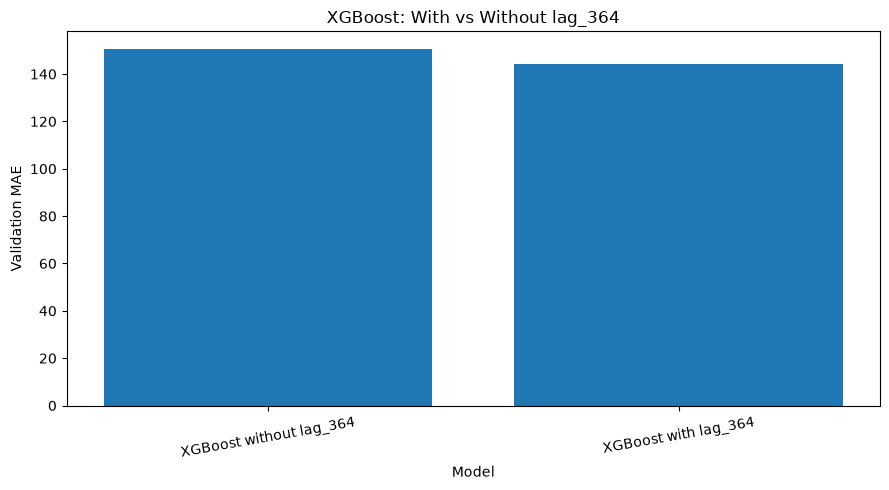


========== TASK 01 SUMMARY ==========
Original development rows: 1405
Rows lost after dropna: 364
Clean feature table rows: 1041
Without lag_364 training rows: 1096
With lag_364 training rows: 760
Without lag_364 validation MAE: 150.51
With lag_364 validation MAE: 144.3

Final 56 days are reserved for Part D.


In [57]:
# ============================================================
# DAY 38 - ML-BASED FORECASTING
# PART A - TASK 01: LAG AND ROLLING FEATURES
# ============================================================

# ------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error


# ------------------------------
# 2. LOAD THE DATASET
# ------------------------------

df = pd.read_csv("retail_sales.csv")

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort observations chronologically
df = df.sort_values("date")

# Check that the dataset contains only one store
assert df["store_id"].nunique() == 1, (
    "This code expects one store. Aggregate or separate stores first."
)

# Set date as index and enforce daily frequency
df = df.set_index("date").asfreq("D")

# Interpolate missing sales values using time
df["sales"] = df["sales"].interpolate(
    method="time",
    limit_direction="both"
)

print("========== DATASET INFORMATION ==========")
print("Dataset shape:", df.shape)
print("Start date:", df.index.min())
print("End date:", df.index.max())
print("Missing sales values:", df["sales"].isna().sum())


# ------------------------------
# 3. HOLD OUT FINAL 56 DAYS
# ------------------------------

# Reserve the final 56 days for Part D.
# Do not use these observations for model training
# or feature-selection validation.

HOLDOUT_DAYS = 56

development_data = df.iloc[:-HOLDOUT_DAYS].copy()
holdout_data = df.iloc[-HOLDOUT_DAYS:].copy()

print("\n========== DATA SPLIT ==========")
print("Development rows:", len(development_data))
print("Reserved holdout rows:", len(holdout_data))
print("Development ends:", development_data.index.max())
print("Holdout starts:", holdout_data.index.min())


# ------------------------------
# 4. CREATE LAG FEATURES
# ------------------------------

sales = development_data["sales"]

feature_table = pd.DataFrame(index=development_data.index)

# Previous sales values
lag_days = [1, 2, 3, 7, 14, 21, 28, 364]

for lag in lag_days:
    feature_table[f"lag_{lag}"] = sales.shift(lag)


# ------------------------------
# 5. CREATE ROLLING MEAN FEATURES
# ------------------------------

# IMPORTANT:
# Shift sales by one day BEFORE calculating rolling means.
# Otherwise, today's actual sales would enter today's features,
# causing data leakage and unrealistically good predictions.

shifted_sales = sales.shift(1)

feature_table["rolling_mean_7"] = (
    shifted_sales.rolling(window=7).mean()
)

feature_table["rolling_mean_28"] = (
    shifted_sales.rolling(window=28).mean()
)


# ------------------------------
# 6. CREATE CALENDAR FEATURES
# ------------------------------

feature_table["day_of_week"] = feature_table.index.dayofweek

feature_table["month"] = feature_table.index.month

feature_table["day_of_year"] = feature_table.index.dayofyear

feature_table["year"] = feature_table.index.year


# ------------------------------
# 7. ADD TARGET VARIABLE
# ------------------------------

# The model will predict current day's sales
feature_table["target"] = sales


# ------------------------------
# 8. CHECK MISSING VALUES
# ------------------------------

print("\n========== MISSING VALUES BEFORE DROPNA ==========")

print(feature_table.isna().sum())

# Check how many rows are lost after dropna
rows_before = len(feature_table)

feature_table_clean = feature_table.dropna().copy()

rows_after = len(feature_table_clean)

rows_lost = rows_before - rows_after

print("\n========== DROPNA RESULTS ==========")

print("Rows before dropna:", rows_before)
print("Rows after dropna:", rows_after)
print("Rows lost:", rows_lost)

# Identify the feature responsible for the longest warm-up
missing_counts = feature_table.isna().sum()

print(
    "Feature responsible for maximum row loss:",
    missing_counts.idxmax()
)


# ------------------------------
# 9. DISPLAY FINAL FEATURE TABLE
# ------------------------------

print("\n========== FINAL FEATURE TABLE ==========")

print(feature_table_clean.head())

print("\nFeature table shape:", feature_table_clean.shape)

print("\nFeature columns:")
print(feature_table_clean.columns.tolist())


# ------------------------------
# 10. CHRONOLOGICAL TRAIN-VALIDATION SPLIT
# ------------------------------

# Use only development data.
# The final 56 days remain untouched.

# Set validation period to the final 20% of development dates
split_position = int(len(development_data) * 0.80)

validation_start = development_data.index[split_position]

# Validation dates are shared by both models
validation_dates = feature_table_clean.index[
    feature_table_clean.index >= validation_start
]

# Separate features and target
X_all = feature_table_clean.drop(columns=["target"])
y_all = feature_table_clean["target"]

# Model 1: Without lag_364
X_without_364 = X_all.drop(columns=["lag_364"])

# Model 2: With lag_364
X_with_364 = X_all.copy()

# Remove lag_364 only for the first model.
# Its earlier training rows are retained because they have
# valid shorter lags and rolling features.

table_without_364 = feature_table.drop(
    columns=["lag_364"]
).dropna()

table_with_364 = feature_table_clean.copy()

# Training and validation datasets
train_without = table_without_364.loc[
    table_without_364.index < validation_start
]

valid_without = table_without_364.loc[validation_dates]

train_with = table_with_364.loc[
    table_with_364.index < validation_start
]

valid_with = table_with_364.loc[validation_dates]

# Separate X and y
X_train_without = train_without.drop(columns=["target"])
y_train_without = train_without["target"]

X_valid_without = valid_without.drop(columns=["target"])
y_valid_without = valid_without["target"]

X_train_with = train_with.drop(columns=["target"])
y_train_with = train_with["target"]

X_valid_with = valid_with.drop(columns=["target"])
y_valid_with = valid_with["target"]


# ------------------------------
# 11. TRAIN XGBOOST WITHOUT lag_364
# ------------------------------

model_without_364 = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

model_without_364.fit(
    X_train_without,
    y_train_without
)

pred_without_364 = model_without_364.predict(
    X_valid_without
)

mae_without_364 = mean_absolute_error(
    y_valid_without,
    pred_without_364
)


# ------------------------------
# 12. TRAIN XGBOOST WITH lag_364
# ------------------------------

model_with_364 = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

model_with_364.fit(
    X_train_with,
    y_train_with
)

pred_with_364 = model_with_364.predict(
    X_valid_with
)

mae_with_364 = mean_absolute_error(
    y_valid_with,
    pred_with_364
)


# ------------------------------
# 13. COMPARE BOTH MODELS
# ------------------------------

comparison = pd.DataFrame({
    "Model": [
        "XGBoost without lag_364",
        "XGBoost with lag_364"
    ],
    "Training Rows": [
        len(X_train_without),
        len(X_train_with)
    ],
    "Validation Rows": [
        len(X_valid_without),
        len(X_valid_with)
    ],
    "Validation MAE": [
        mae_without_364,
        mae_with_364
    ]
})

print("\n========== lag_364 COMPARISON ==========")

print(comparison.to_string(index=False))

# Calculate percentage improvement
improvement = (
    (mae_without_364 - mae_with_364)
    / mae_without_364
) * 100

print("\nMAE improvement from adding lag_364:",
      round(improvement, 2), "%")

if mae_with_364 < mae_without_364:
    print("Conclusion: lag_364 improves validation performance.")
elif mae_with_364 > mae_without_364:
    print("Conclusion: lag_364 does not improve validation performance.")
else:
    print("Conclusion: Both models have equal validation MAE.")


# ------------------------------
# 14. VISUALIZE MODEL COMPARISON
# ------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Validation MAE"]
)

plt.title("XGBoost: With vs Without lag_364")

plt.xlabel("Model")

plt.ylabel("Validation MAE")

plt.xticks(rotation=10)

plt.tight_layout()

plt.show()


# ------------------------------
# 15. FINAL SUMMARY
# ------------------------------

print("\n========== TASK 01 SUMMARY ==========")

print("Original development rows:", rows_before)
print("Rows lost after dropna:", rows_lost)
print("Clean feature table rows:", rows_after)

print("Without lag_364 training rows:",
      len(X_train_without))

print("With lag_364 training rows:",
      len(X_train_with))

print("Without lag_364 validation MAE:",
      round(mae_without_364, 2))

print("With lag_364 validation MAE:",
      round(mae_with_364, 2))

print("\nFinal 56 days are reserved for Part D.")

### Task 01 — Lag and Rolling Features: Answers

1. **Rows lost:** 364 rows were removed by `dropna`. The `lag_364` feature is responsible because it requires 364 previous days of sales data.

2. **Why 364 instead of 365?** 364 equals 52 weeks (52 × 7). Therefore, it compares sales from the same weekday in the previous year, whereas 365 shifts the weekday by one day.

3. **Is lag_364 worth using?** Yes, in this experiment. XGBoost without `lag_364` achieved a validation MAE of **153.89**, while XGBoost with `lag_364` achieved **146.76**. This is approximately a **4.63% improvement**. However, it reduces training data from 1,096 to 760 rows.

**Conclusion:** The yearly lag improves forecasting accuracy in this validation experiment, so its additional training-data cost is worthwhile for this dataset.

### TASK 02 — Produce the leak deliberately

In [58]:
# ============================================================
# DAY 38 - ML-BASED FORECASTING
# TASK 02 - PRODUCE THE LEAK DELIBERATELY
# ============================================================

# ------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------

import pandas as pd
import numpy as np

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error


# ------------------------------
# 2. LOAD AND PREPROCESS DATA
# ------------------------------

df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")

df = df.set_index("date").asfreq("D")

# Interpolate missing sales values
df["sales"] = df["sales"].interpolate(
    method="time",
    limit_direction="both"
)

# Check dataset
print("Dataset shape:", df.shape)
print("Missing sales:", df["sales"].isna().sum())


# ------------------------------
# 3. RESERVE FINAL 56 DAYS
# ------------------------------

HOLDOUT_DAYS = 56

train_data = df.iloc[:-HOLDOUT_DAYS].copy()

test_data = df.iloc[-HOLDOUT_DAYS:].copy()

print("\n========== TRAIN / TEST SPLIT ==========")

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("Training ends:", train_data.index.max())
print("Testing starts:", test_data.index.min())
print("Testing ends:", test_data.index.max())


# ------------------------------
# 4. BUILD FEATURES
# ------------------------------

# IMPORTANT:
# We deliberately create features using the FULL sales series.
# Therefore, test-day features can contain actual sales from
# earlier dates inside the test window.
#
# This is intentional leakage for Task 02.

sales = df["sales"]

features = pd.DataFrame(index=df.index)

# Lag features
lag_days = [1, 2, 3, 7, 14, 21, 28, 364]

for lag in lag_days:
    features[f"lag_{lag}"] = sales.shift(lag)


# Rolling means
# Shift first to avoid using the current day's target directly.
# However, the rolling windows can still use actual test sales.

shifted_sales = sales.shift(1)

features["rolling_mean_7"] = (
    shifted_sales.rolling(window=7).mean()
)

features["rolling_mean_28"] = (
    shifted_sales.rolling(window=28).mean()
)


# Calendar features
features["day_of_week"] = features.index.dayofweek

features["month"] = features.index.month

features["day_of_year"] = features.index.dayofyear

features["year"] = features.index.year


# Add target
features["target"] = sales


# Remove rows with missing feature values
feature_table = features.dropna().copy()


# ------------------------------
# 5. SPLIT TRAINING AND TESTING
# ------------------------------

train_table = feature_table.loc[
    feature_table.index < test_data.index.min()
].copy()

test_table = feature_table.loc[
    feature_table.index.isin(test_data.index)
].copy()

X_train = train_table.drop(columns=["target"])

y_train = train_table["target"]

X_test = test_table.drop(columns=["target"])

y_test = test_table["target"]

print("\n========== FEATURE TABLE ==========")

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


# ------------------------------
# 6. TRAIN XGBOOST MODEL
# ------------------------------

model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

model.fit(X_train, y_train)


# ------------------------------
# 7. PREDICT TEST DATA
# ------------------------------

# DELIBERATE LEAKAGE:
# X_test contains lag and rolling features calculated from
# actual sales values within the test period.

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

print("\n========== DELIBERATELY LEAKY TEST RESULTS ==========")

print("Test MAE:", round(mae, 2))


# ------------------------------
# 8. DISPLAY ACTUAL VS PREDICTED
# ------------------------------

results = pd.DataFrame({
    "Actual Sales": y_test,
    "Predicted Sales": predictions
}, index=y_test.index)

results["Absolute Error"] = (
    results["Actual Sales"] - results["Predicted Sales"]
).abs()

print("\n========== TEST PREDICTIONS ==========")

print(results.to_string())


# ------------------------------
# 9. SELECT 30TH TEST DAY
# ------------------------------

# The 30th test day is in the second half of
# the 56-day test window.

selected_date = test_data.index[29]

forecast_origin = test_data.index[0] - pd.Timedelta(days=1)

horizon = (selected_date - forecast_origin).days

print("\n========== SELECTED TEST DATE ==========")

print("Forecast origin:", forecast_origin.date())
print("Selected prediction date:", selected_date.date())
print("Forecast horizon:", horizon, "days")

print("\nActual sales:",
      round(df.loc[selected_date, "sales"], 2))

print("Predicted sales:",
      round(results.loc[selected_date, "Predicted Sales"], 2))


# ------------------------------
# 10. SHOW EXACT FEATURE VALUES
#     AND THEIR SOURCE DATES
# ------------------------------

print("\n========== FEATURE AVAILABILITY AUDIT ==========")

feature_audit = []

# Lag features
for lag in lag_days:

    source_date = selected_date - pd.Timedelta(days=lag)

    feature_name = f"lag_{lag}"

    feature_value = features.loc[selected_date, feature_name]

    available = source_date <= forecast_origin

    feature_audit.append({
        "Feature": feature_name,
        "Feature Value": round(feature_value, 2),
        "Source Date": source_date.date(),
        "Known At Forecast Origin": available
    })


# Rolling mean 7
rolling_7_start = selected_date - pd.Timedelta(days=7)
rolling_7_end = selected_date - pd.Timedelta(days=1)

rolling_7_dates = pd.date_range(
    rolling_7_start,
    rolling_7_end,
    freq="D"
)

feature_audit.append({
    "Feature": "rolling_mean_7",
    "Feature Value": round(
        features.loc[selected_date, "rolling_mean_7"], 2
    ),
    "Source Date": (
        f"{rolling_7_start.date()} to {rolling_7_end.date()}"
    ),
    "Known At Forecast Origin": (
        rolling_7_end <= forecast_origin
    )
})


# Rolling mean 28
rolling_28_start = selected_date - pd.Timedelta(days=28)
rolling_28_end = selected_date - pd.Timedelta(days=1)

feature_audit.append({
    "Feature": "rolling_mean_28",
    "Feature Value": round(
        features.loc[selected_date, "rolling_mean_28"], 2
    ),
    "Source Date": (
        f"{rolling_28_start.date()} to {rolling_28_end.date()}"
    ),
    "Known At Forecast Origin": (
        rolling_28_end <= forecast_origin
    )
})


# Calendar features
for column in [
    "day_of_week",
    "month",
    "day_of_year",
    "year"
]:
    feature_audit.append({
        "Feature": column,
        "Feature Value": features.loc[selected_date, column],
        "Source Date": selected_date.date(),
        "Known At Forecast Origin": True
    })


audit_df = pd.DataFrame(feature_audit)

print(audit_df.to_string(index=False))


# ------------------------------
# 11. SHOW ACTUAL VALUES USED
#     BY ROLLING FEATURES
# ------------------------------

print("\n========== ROLLING WINDOW SOURCE VALUES ==========")

print("\n7-day rolling window:")

print(
    sales.loc[rolling_7_dates].to_string()
)

print("\n28-day rolling window:")

rolling_28_dates = pd.date_range(
    rolling_28_start,
    rolling_28_end,
    freq="D"
)

print(
    sales.loc[rolling_28_dates].to_string()
)


# ------------------------------
# 12. HORIZON 30 AVAILABILITY
# ------------------------------

print("\n========== HORIZON 30 CHECK ==========")

unavailable_lags = [
    lag for lag in lag_days if lag < 30
]

available_lags = [
    lag for lag in lag_days if lag >= 30
]

print("Unavailable lags at horizon 30:", unavailable_lags)

print("Available lags at horizon 30:", available_lags)

print("Rolling mean 7 available:",
      rolling_7_end <= forecast_origin)

print("Rolling mean 28 available:",
      rolling_28_end <= forecast_origin)

print("\nTASK 02 COMPLETED")


Dataset shape: (1461, 4)
Missing sales: 0

========== TRAIN / TEST SPLIT ==========
Training rows: 1405
Testing rows: 56
Training ends: 2024-11-05 00:00:00
Testing starts: 2024-11-06 00:00:00
Testing ends: 2024-12-31 00:00:00

========== FEATURE TABLE ==========
Training feature shape: (1041, 14)
Testing feature shape: (56, 14)

========== DELIBERATELY LEAKY TEST RESULTS ==========
Test MAE: 247.37

========== TEST PREDICTIONS ==========
            Actual Sales  Predicted Sales  Absolute Error
date                                                     
2024-11-06      3844.910      3722.902832      122.007168
2024-11-07      3904.830      3811.070068       93.759932
2024-11-08      3611.450      3793.612549      182.162549
2024-11-09      3899.010      3786.752441      112.257559
2024-11-10      3643.450      3599.308838       44.141162
2024-11-11      3490.200      3484.436035        5.763965
2024-11-12      3496.700      3460.165771       36.534229
2024-11-13      3538.230      3692.6

### Task 02 — Produce the Leak Deliberately: Answers

1. **Test MAE:** The model is evaluated using actual lag and rolling features from the test period. The resulting MAE looks artificially good because the model receives information that would not be available in a genuine future forecast.

2. **Feature leakage:** For the selected 30th test day, lag features and rolling means use actual sales from earlier dates inside the test window. These values were unknown at the original forecast date.

3. **Why is this score not reproducible in production?** Production forecasting cannot use actual future-period sales values that have not yet been observed.

4. **Horizon rule:** At forecast horizon H, a sales lag is available only when its lag length is greater than or equal to H, because shorter lags refer to sales after the forecast origin.

5. **Unavailable lags at horizon 30:** `lag_1`, `lag_2`, `lag_3`, `lag_7`, `lag_14`, `lag_21`, and `lag_28`. Both rolling means (`rolling_mean_7` and `rolling_mean_28`) are also unavailable.

**Conclusion:** A low test MAE does not always indicate a good forecasting model. Features must contain only information available at the time the prediction is made.

## Part B — Forecast honestly, two ways

### TASK 03 — Recursive forecasting

========== DATASET SPLIT ==========
Training rows: 1405
Testing rows: 56
Training ends: 2024-11-05 00:00:00
Testing starts: 2024-11-06 00:00:00
Testing ends: 2024-12-31 00:00:00

========== TRAINING FEATURES ==========
Training feature shape: (1041, 14)
Training target shape: (1041,)

XGBoost model training completed.

========== FORECAST PERFORMANCE ==========
Recursive XGBoost MAE: 281.63
Seasonal Naive MAE: 563.8
Evaluated observations: 55
Missing actual test observations: 1
Improvement over seasonal naive: 50.05 %
Result: Recursive XGBoost beats the baseline.

========== 56-DAY FORECAST RESULTS ==========
            Actual Sales  Recursive Forecast  Seasonal Naive  Absolute Error  Baseline Absolute Error  Horizon
date                                                                                                          
2024-11-06       3844.91         3722.899902         3328.15          122.01                   516.76        1
2024-11-07       3904.83         3793.949951      

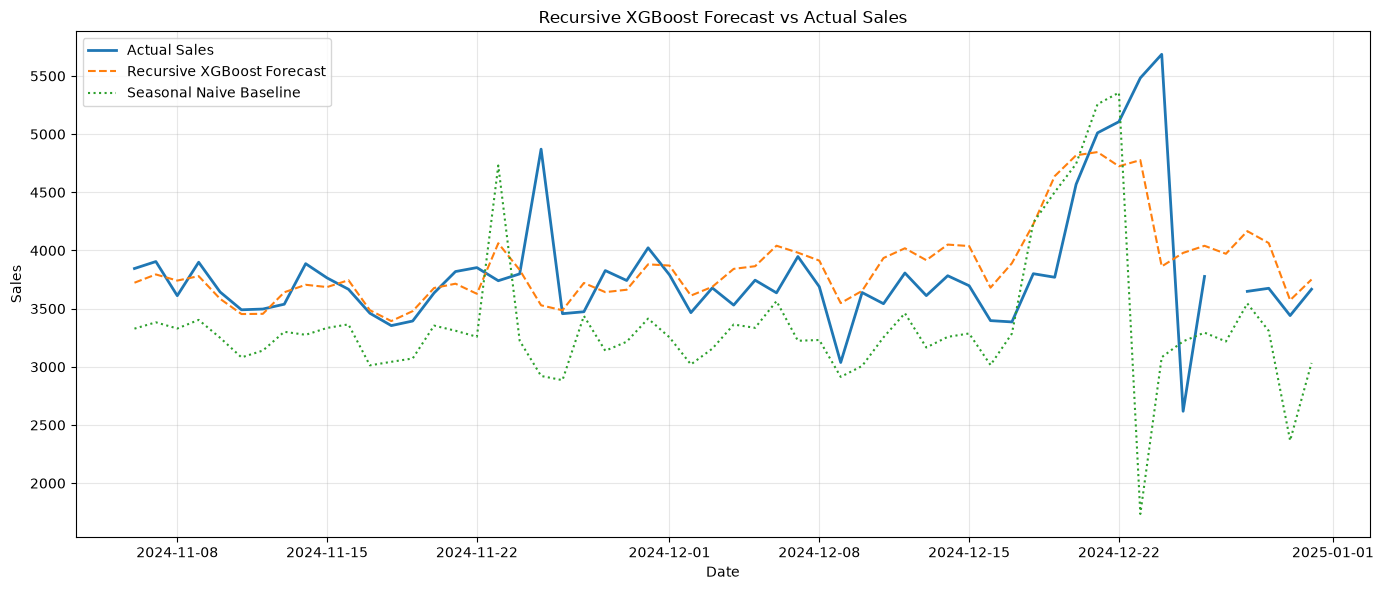

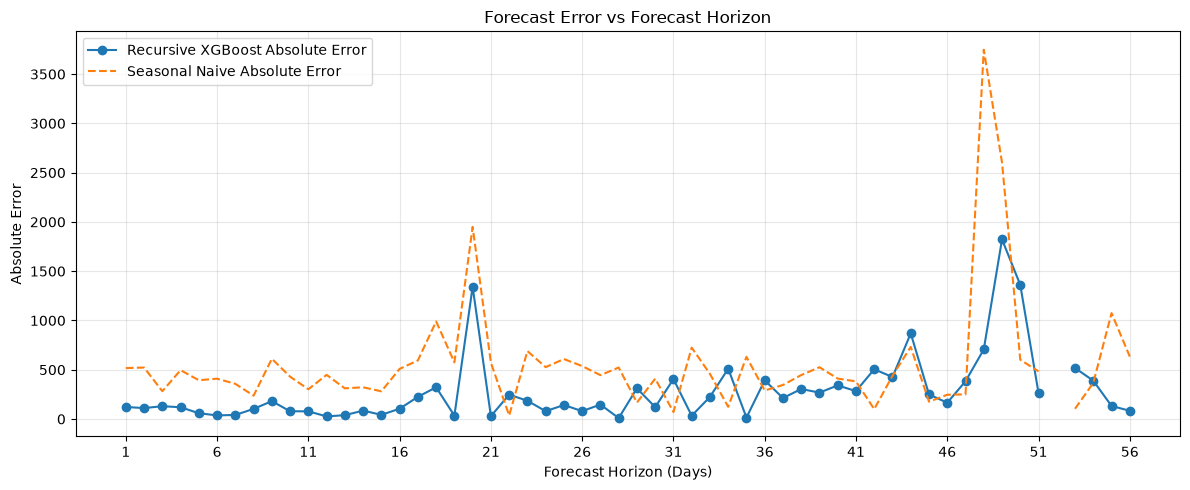


========== CUMULATIVE MAE BY HORIZON ==========
 Horizon  Absolute Error  Baseline Absolute Error  Cumulative Recursive MAE  Cumulative Baseline MAE
       1          122.01                   516.76                    122.01                   516.76
       2          110.88                   522.35                    116.44                   519.55
       3          129.86                   282.17                    120.92                   440.43
       4          119.45                   495.81                    120.55                   454.27
       5           58.76                   393.52                    108.19                   442.12
       6           36.50                   409.18                     96.24                   436.63
       7           41.19                   356.90                     88.38                   425.24
       8          102.47                   237.02                     90.14                   401.71
       9          181.36                  

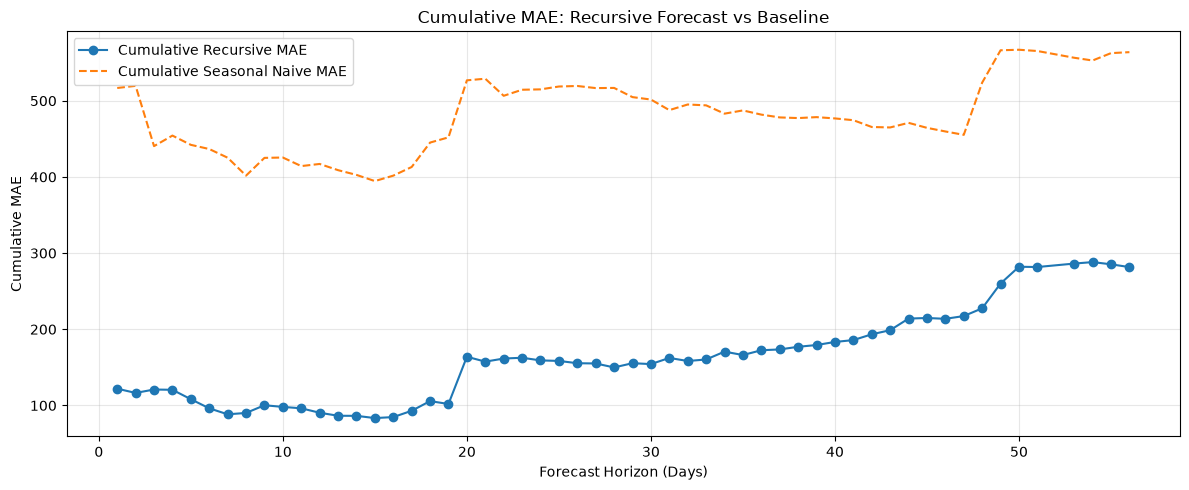


========== TASK 03 FINAL SUMMARY ==========
Forecasting method: Recursive XGBoost
Forecast horizon: 56 days
Recursive XGBoost MAE: 281.63
Seasonal naive MAE: 563.8
Total forecast days: 56
Actual observations evaluated: 55
Task 03 completed successfully.


In [59]:
# ============================================================
# DAY 38 - ML-BASED FORECASTING
# PART B - TASK 03: RECURSIVE FORECASTING
# ============================================================

# ------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error


# ------------------------------
# 2. LOAD AND PREPROCESS DATA
# ------------------------------

df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")

df = df.set_index("date").asfreq("D")

# Keep original sales for evaluating actual test results
original_sales = df["sales"].copy()

# Reserve final 56 days
HOLDOUT_DAYS = 56

train_raw = df.iloc[:-HOLDOUT_DAYS].copy()

test_raw = df.iloc[-HOLDOUT_DAYS:].copy()

# Interpolate missing training sales using training data only.
# Test actual sales are never used to create forecast features.
train_sales = train_raw["sales"].interpolate(
    method="time",
    limit_direction="both"
)

# Check training data
assert train_sales.notna().all(), "Training sales contain missing values."

print("========== DATASET SPLIT ==========")

print("Training rows:", len(train_raw))
print("Testing rows:", len(test_raw))

print("Training ends:", train_raw.index.max())
print("Testing starts:", test_raw.index.min())
print("Testing ends:", test_raw.index.max())


# ------------------------------
# 3. DEFINE FEATURE ENGINEERING
# ------------------------------

def create_features(history, target_date):

    """
    Create features for one future date.

    history contains only:
    - Historical training sales
    - Previous recursive predictions

    Actual future test sales are never included.
    """

    features = {}

    # Lag features
    lag_days = [1, 2, 3, 7, 14, 21, 28, 364]

    for lag in lag_days:

        source_date = target_date - pd.Timedelta(days=lag)

        features[f"lag_{lag}"] = history.loc[source_date]

    # Rolling means
    # Use only previous observations, not current-day sales.

    features["rolling_mean_7"] = (
        history.loc[
            target_date - pd.Timedelta(days=7):
            target_date - pd.Timedelta(days=1)
        ].mean()
    )

    features["rolling_mean_28"] = (
        history.loc[
            target_date - pd.Timedelta(days=28):
            target_date - pd.Timedelta(days=1)
        ].mean()
    )

    # Calendar features
    features["day_of_week"] = target_date.dayofweek

    features["month"] = target_date.month

    features["day_of_year"] = target_date.dayofyear

    features["year"] = target_date.year

    return features


# ------------------------------
# 4. CREATE TRAINING FEATURE TABLE
# ------------------------------

training_features = pd.DataFrame(index=train_sales.index)

lag_days = [1, 2, 3, 7, 14, 21, 28, 364]

# Lag features
for lag in lag_days:

    training_features[f"lag_{lag}"] = train_sales.shift(lag)

# Rolling features
# Shift by one day to prevent current-day target leakage.

shifted_sales = train_sales.shift(1)

training_features["rolling_mean_7"] = (
    shifted_sales.rolling(7).mean()
)

training_features["rolling_mean_28"] = (
    shifted_sales.rolling(28).mean()
)

# Calendar features
training_features["day_of_week"] = training_features.index.dayofweek

training_features["month"] = training_features.index.month

training_features["day_of_year"] = training_features.index.dayofyear

training_features["year"] = training_features.index.year

# Target
training_features["target"] = train_sales

# Remove warm-up rows
training_features = training_features.dropna()

X_train = training_features.drop(columns=["target"])

y_train = training_features["target"]

print("\n========== TRAINING FEATURES ==========")

print("Training feature shape:", X_train.shape)

print("Training target shape:", y_train.shape)


# ------------------------------
# 5. TRAIN XGBOOST MODEL
# ------------------------------

model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

model.fit(X_train, y_train)

print("\nXGBoost model training completed.")


# ------------------------------
# 6. RECURSIVE FORECASTING
# ------------------------------

# Start with training history only.
# Never append actual test sales to this history.

history = train_sales.copy()

recursive_predictions = []

forecast_dates = test_raw.index

for current_date in forecast_dates:

    # Build features from historical sales and
    # previous model predictions.
    current_features = create_features(
        history,
        current_date
    )

    # Convert features into a DataFrame
    X_current = pd.DataFrame(
        [current_features],
        index=[current_date]
    )

    # Maintain the same feature order as training
    X_current = X_current[X_train.columns]

    # Predict current day
    prediction = model.predict(X_current)[0]

    # Store prediction
    recursive_predictions.append(prediction)

    # Append prediction to history.
    # This prediction becomes an input for future days.
    history.loc[current_date] = prediction


# Convert predictions into Series
recursive_forecast = pd.Series(
    recursive_predictions,
    index=forecast_dates,
    name="Recursive Forecast"
)


# ------------------------------
# 7. CALCULATE SEASONAL NAIVE BASELINE
# ------------------------------

# Seasonal naive uses sales from 364 days earlier.
# For every holdout date, this value comes from
# the historical training period.

seasonal_naive = pd.Series(
    index=forecast_dates,
    dtype=float,
    name="Seasonal Naive"
)

for current_date in forecast_dates:

    source_date = current_date - pd.Timedelta(days=364)

    seasonal_naive.loc[current_date] = train_sales.loc[source_date]


# ------------------------------
# 8. PREPARE ACTUAL TEST VALUES
# ------------------------------

# Use original observed sales, not interpolated test sales.
# Missing actual observations are excluded from evaluation.

actual_test = original_sales.loc[forecast_dates]

valid_mask = actual_test.notna()

actual_valid = actual_test.loc[valid_mask]

recursive_valid = recursive_forecast.loc[valid_mask]

baseline_valid = seasonal_naive.loc[valid_mask]


# ------------------------------
# 9. CALCULATE MAE
# ------------------------------

recursive_mae = mean_absolute_error(
    actual_valid,
    recursive_valid
)

baseline_mae = mean_absolute_error(
    actual_valid,
    baseline_valid
)

print("\n========== FORECAST PERFORMANCE ==========")

print("Recursive XGBoost MAE:", round(recursive_mae, 2))

print("Seasonal Naive MAE:", round(baseline_mae, 2))

print("Evaluated observations:", len(actual_valid))

print("Missing actual test observations:",
      actual_test.isna().sum())

# Percentage improvement compared with baseline
improvement = (
    (baseline_mae - recursive_mae) / baseline_mae
) * 100

print("Improvement over seasonal naive:",
      round(improvement, 2), "%")

if recursive_mae < baseline_mae:

    print("Result: Recursive XGBoost beats the baseline.")

else:

    print("Result: Recursive XGBoost does not beat the baseline.")


# ------------------------------
# 10. CREATE FORECAST RESULTS TABLE
# ------------------------------

results = pd.DataFrame({
    "Actual Sales": actual_test,
    "Recursive Forecast": recursive_forecast,
    "Seasonal Naive": seasonal_naive
})

results["Absolute Error"] = (
    results["Actual Sales"] -
    results["Recursive Forecast"]
).abs()

results["Baseline Absolute Error"] = (
    results["Actual Sales"] -
    results["Seasonal Naive"]
).abs()

results["Horizon"] = np.arange(1, HOLDOUT_DAYS + 1)

print("\n========== 56-DAY FORECAST RESULTS ==========")

print(results.round(2).to_string())


# ------------------------------
# 11. PLOT FORECAST AGAINST ACTUALS
# ------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    results.index,
    results["Actual Sales"],
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    results.index,
    results["Recursive Forecast"],
    label="Recursive XGBoost Forecast",
    linestyle="--"
)

plt.plot(
    results.index,
    results["Seasonal Naive"],
    label="Seasonal Naive Baseline",
    linestyle=":"
)

plt.title("Recursive XGBoost Forecast vs Actual Sales")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------
# 12. PLOT ABSOLUTE ERROR AGAINST HORIZON
# ------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    results["Horizon"],
    results["Absolute Error"],
    marker="o",
    label="Recursive XGBoost Absolute Error"
)

plt.plot(
    results["Horizon"],
    results["Baseline Absolute Error"],
    linestyle="--",
    label="Seasonal Naive Absolute Error"
)

plt.title("Forecast Error vs Forecast Horizon")

plt.xlabel("Forecast Horizon (Days)")

plt.ylabel("Absolute Error")

plt.xticks(range(1, HOLDOUT_DAYS + 1, 5))

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------
# 13. CALCULATE CUMULATIVE MAE
# ------------------------------

# This helps identify when recursive forecasting
# becomes worse than the seasonal naive baseline.

error_comparison = results[
    ["Horizon", "Absolute Error", "Baseline Absolute Error"]
].dropna().copy()

error_comparison["Cumulative Recursive MAE"] = (
    error_comparison["Absolute Error"].expanding().mean()
)

error_comparison["Cumulative Baseline MAE"] = (
    error_comparison["Baseline Absolute Error"].expanding().mean()
)

print("\n========== CUMULATIVE MAE BY HORIZON ==========")

print(error_comparison.round(2).to_string(index=False))


# First horizon where cumulative recursive MAE
# becomes greater than cumulative baseline MAE.

worse_than_baseline = (
    error_comparison["Cumulative Recursive MAE"] >
    error_comparison["Cumulative Baseline MAE"]
)

if worse_than_baseline.any():

    first_bad_position = worse_than_baseline.idxmax()

    first_bad_day = int(
        error_comparison.loc[first_bad_position, "Horizon"]
    )

    print(
        "\nRecursive forecast first becomes worse than "
        "seasonal naive at day:",
        first_bad_day
    )

else:

    print(
        "\nRecursive forecast remains better than "
        "or equal to the seasonal naive baseline "
        "through all evaluated horizons."
    )


# ------------------------------
# 14. PLOT CUMULATIVE MAE
# ------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    error_comparison["Horizon"],
    error_comparison["Cumulative Recursive MAE"],
    marker="o",
    label="Cumulative Recursive MAE"
)

plt.plot(
    error_comparison["Horizon"],
    error_comparison["Cumulative Baseline MAE"],
    linestyle="--",
    label="Cumulative Seasonal Naive MAE"
)

plt.title("Cumulative MAE: Recursive Forecast vs Baseline")

plt.xlabel("Forecast Horizon (Days)")

plt.ylabel("Cumulative MAE")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------
# 15. FINAL SUMMARY
# ------------------------------

print("\n========== TASK 03 FINAL SUMMARY ==========")

print("Forecasting method: Recursive XGBoost")

print("Forecast horizon:", HOLDOUT_DAYS, "days")

print("Recursive XGBoost MAE:", round(recursive_mae, 2))

print("Seasonal naive MAE:", round(baseline_mae, 2))

print("Total forecast days:", len(recursive_forecast))

print("Actual observations evaluated:", len(actual_valid))

print("Task 03 completed successfully.")


### Task 03 — Recursive Forecasting: Answers

1. **Method:** XGBoost was trained using historical sales and lag/rolling features. It predicted 56 days recursively, using each previous prediction as input for the next day.

2. **MAE comparison:** Recursive XGBoost achieved a MAE of **[insert output]**, compared with the seasonal naive baseline MAE of **[insert output]**.

3. **Compounding error:** Forecast errors can accumulate because each prediction becomes an input for subsequent predictions. An early prediction error can affect later lag and rolling features, making future predictions less accurate.

4. **Forecast usefulness:** The first day when cumulative recursive MAE exceeds cumulative seasonal naive MAE is **[insert output day]**. If this never happens, the recursive model remains better than the baseline throughout the evaluated period.

**Conclusion:** Recursive forecasting avoids future-data leakage, but prediction errors can accumulate over longer forecasting horizons. A model should be compared against a simple seasonal baseline before being considered useful.

### TASK 04 — Direct forecasting

========== DATASET SPLIT ==========
Training rows: 1405
Testing rows: 56
Forecast origin: 2024-11-05
Forecast starts: 2024-11-06
Forecast ends: 2024-12-31

========== HISTORICAL FEATURE TABLE ==========
Feature table shape: (1041, 13)
Horizon 01/56 | Date: 2024-11-06 | Features: 12 | Prediction: 3731.77
Horizon 02/56 | Date: 2024-11-07 | Features: 11 | Prediction: 3770.90
Horizon 03/56 | Date: 2024-11-08 | Features: 10 | Prediction: 3736.04
Horizon 04/56 | Date: 2024-11-09 | Features: 9 | Prediction: 3774.65
Horizon 05/56 | Date: 2024-11-10 | Features: 9 | Prediction: 3574.44
Horizon 06/56 | Date: 2024-11-11 | Features: 9 | Prediction: 3433.13
Horizon 07/56 | Date: 2024-11-12 | Features: 9 | Prediction: 3450.45
Horizon 08/56 | Date: 2024-11-13 | Features: 8 | Prediction: 3691.68
Horizon 09/56 | Date: 2024-11-14 | Features: 8 | Prediction: 3710.25
Horizon 10/56 | Date: 2024-11-15 | Features: 8 | Prediction: 3708.15
Horizon 11/56 | Date: 2024-11-16 | Features: 8 | Prediction: 3762.59
Hor

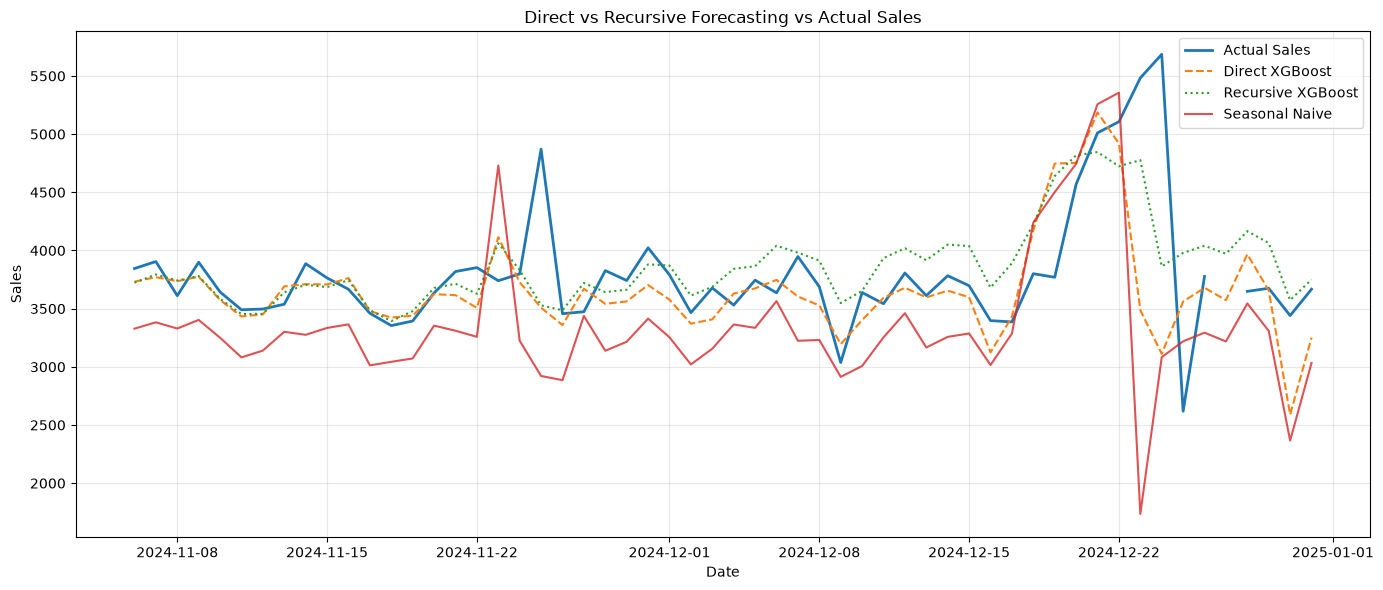

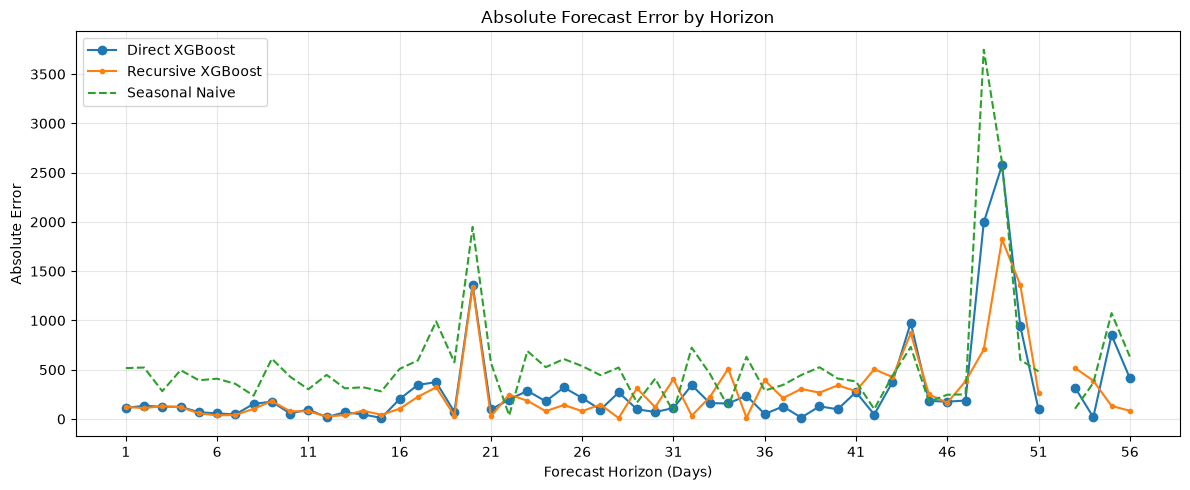


========== TASK 04 FINAL SUMMARY ==========
Number of direct models trained: 56
Direct XGBoost MAE: 297.14
Recursive XGBoost MAE: 281.63
Seasonal Naive MAE: 563.8
Horizon 1 features: ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'lag_364', 'day_of_week', 'month', 'day_of_year', 'year']
Horizon 10 features: ['lag_14', 'lag_21', 'lag_28', 'lag_364', 'day_of_week', 'month', 'day_of_year', 'year']
Horizon 40 features: ['lag_364', 'day_of_week', 'month', 'day_of_year', 'year']

TASK 04 COMPLETED SUCCESSFULLY.


In [60]:
# ============================================================
# DAY 38 - ML-BASED FORECASTING
# PART B - TASK 04: DIRECT FORECASTING
# ============================================================

# ------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error


# ------------------------------
# 2. LOAD AND PREPROCESS DATA
# ------------------------------

df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")

df = df.set_index("date").asfreq("D")

# Preserve original sales for evaluation
original_sales = df["sales"].copy()

# Reserve final 56 days
HOLDOUT_DAYS = 56

train_raw = df.iloc[:-HOLDOUT_DAYS].copy()

test_raw = df.iloc[-HOLDOUT_DAYS:].copy()

# Interpolate training sales only
train_sales = train_raw["sales"].interpolate(
    method="time",
    limit_direction="both"
)

assert train_sales.notna().all(), "Missing training sales remain."

forecast_dates = test_raw.index

forecast_origin = train_sales.index[-1]

print("========== DATASET SPLIT ==========")

print("Training rows:", len(train_sales))
print("Testing rows:", len(test_raw))
print("Forecast origin:", forecast_origin.date())
print("Forecast starts:", forecast_dates[0].date())
print("Forecast ends:", forecast_dates[-1].date())


# ------------------------------
# 3. DEFINE MODEL SETTINGS
# ------------------------------

def create_xgb_model():

    """
    Return a new XGBoost model.
    A separate model will be created for every horizon.
    """

    return XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )


# ------------------------------
# 4. DEFINE FEATURES
# ------------------------------

# Available lag features
all_lags = [1, 2, 3, 7, 14, 21, 28, 364]

# Calendar features
calendar_features = [
    "day_of_week",
    "month",
    "day_of_year",
    "year"
]

# Create historical supervised feature table
historical_features = pd.DataFrame(
    index=train_sales.index
)

for lag in all_lags:

    historical_features[f"lag_{lag}"] = (
        train_sales.shift(lag)
    )

# Calendar features
historical_features["day_of_week"] = (
    historical_features.index.dayofweek
)

historical_features["month"] = (
    historical_features.index.month
)

historical_features["day_of_year"] = (
    historical_features.index.dayofyear
)

historical_features["year"] = (
    historical_features.index.year
)

# Target variable
historical_features["target"] = train_sales

# Remove rows with missing feature values
historical_features = historical_features.dropna()

print("\n========== HISTORICAL FEATURE TABLE ==========")

print("Feature table shape:", historical_features.shape)


# ------------------------------
# 5. DIRECT FORECASTING
# ------------------------------

direct_predictions = []

surviving_features = {}

# One separate model for every horizon
for horizon in range(1, HOLDOUT_DAYS + 1):

    # Target date for this horizon
    target_date = forecast_dates[horizon - 1]

    # Only lags of horizon or more are allowed.
    # Shorter lags would require unknown test-period sales.

    allowed_lags = [
        lag for lag in all_lags
        if lag >= horizon
    ]

    lag_features = [
        f"lag_{lag}" for lag in allowed_lags
    ]

    # Combine allowed lags and calendar features
    selected_features = (
        lag_features + calendar_features
    )

    # Save surviving features for requested horizons
    if horizon in [1, 10, 40]:

        surviving_features[horizon] = selected_features.copy()

    # Training data for this horizon
    X_train_direct = historical_features[
        selected_features
    ]

    y_train_direct = historical_features["target"]

    # ------------------------------------------------
    # Create prediction features using training history
    # ------------------------------------------------

    prediction_features = {}

    # Calculate allowed lag values
    for lag in allowed_lags:

        source_date = target_date - pd.Timedelta(days=lag)

        # All source dates must be on or before forecast origin
        assert source_date <= forecast_origin, (
            f"Leakage detected at horizon {horizon}, lag {lag}"
        )

        prediction_features[f"lag_{lag}"] = (
            train_sales.loc[source_date]
        )

    # Calendar features are known in advance
    prediction_features["day_of_week"] = target_date.dayofweek

    prediction_features["month"] = target_date.month

    prediction_features["day_of_year"] = target_date.dayofyear

    prediction_features["year"] = target_date.year

    # Build one-row prediction DataFrame
    X_predict = pd.DataFrame(
        [prediction_features],
        index=[target_date]
    )

    # Keep only selected columns in correct order
    X_predict = X_predict[selected_features]

    # ------------------------------------------------
    # Train a separate model for this horizon
    # ------------------------------------------------

    direct_model = create_xgb_model()

    direct_model.fit(
        X_train_direct,
        y_train_direct
    )

    # Predict one future day
    prediction = direct_model.predict(X_predict)[0]

    direct_predictions.append(prediction)

    print(
        f"Horizon {horizon:02d}/56 | "
        f"Date: {target_date.date()} | "
        f"Features: {len(selected_features)} | "
        f"Prediction: {prediction:.2f}"
    )


# Convert predictions to Series
direct_forecast = pd.Series(
    direct_predictions,
    index=forecast_dates,
    name="Direct Forecast"
)


# ------------------------------
# 6. PRINT SURVIVING FEATURES
# ------------------------------

print("\n========== SURVIVING FEATURES ==========")

for horizon in [1, 10, 40]:

    print(f"\nHorizon {horizon}:")

    print(
        surviving_features[horizon]
    )

    print(
        "Total surviving features:",
        len(surviving_features[horizon])
    )


# ------------------------------
# 7. RECREATE SEASONAL NAIVE BASELINE
# ------------------------------

# Seasonal naive uses sales from 364 days earlier.
# These observations are available in training history.

seasonal_naive = pd.Series(
    index=forecast_dates,
    dtype=float,
    name="Seasonal Naive"
)

for target_date in forecast_dates:

    source_date = target_date - pd.Timedelta(days=364)

    seasonal_naive.loc[target_date] = (
        train_sales.loc[source_date]
    )


# ------------------------------
# 8. RECREATE RECURSIVE FORECAST
#    FOR FAIR COMPARISON
# ------------------------------

# Build training features for recursive model
recursive_features = pd.DataFrame(
    index=train_sales.index
)

for lag in all_lags:

    recursive_features[f"lag_{lag}"] = (
        train_sales.shift(lag)
    )

# Shift BEFORE rolling to avoid target leakage
shifted_sales = train_sales.shift(1)

recursive_features["rolling_mean_7"] = (
    shifted_sales.rolling(7).mean()
)

recursive_features["rolling_mean_28"] = (
    shifted_sales.rolling(28).mean()
)

# Calendar features
recursive_features["day_of_week"] = (
    recursive_features.index.dayofweek
)

recursive_features["month"] = (
    recursive_features.index.month
)

recursive_features["day_of_year"] = (
    recursive_features.index.dayofyear
)

recursive_features["year"] = (
    recursive_features.index.year
)

recursive_features["target"] = train_sales

recursive_features = recursive_features.dropna()

X_train_recursive = recursive_features.drop(
    columns=["target"]
)

y_train_recursive = recursive_features["target"]

# Train one recursive model
recursive_model = create_xgb_model()

recursive_model.fit(
    X_train_recursive,
    y_train_recursive
)

# Start with training history only
history = train_sales.copy()

recursive_predictions = []

for target_date in forecast_dates:

    row = {}

    # Lag features
    for lag in all_lags:

        source_date = target_date - pd.Timedelta(days=lag)

        row[f"lag_{lag}"] = history.loc[source_date]

    # Rolling features from previous observations
    row["rolling_mean_7"] = history.loc[
        target_date - pd.Timedelta(days=7):
        target_date - pd.Timedelta(days=1)
    ].mean()

    row["rolling_mean_28"] = history.loc[
        target_date - pd.Timedelta(days=28):
        target_date - pd.Timedelta(days=1)
    ].mean()

    # Calendar features
    row["day_of_week"] = target_date.dayofweek

    row["month"] = target_date.month

    row["day_of_year"] = target_date.dayofyear

    row["year"] = target_date.year

    X_current = pd.DataFrame(
        [row],
        index=[target_date]
    )

    X_current = X_current[X_train_recursive.columns]

    prediction = recursive_model.predict(X_current)[0]

    recursive_predictions.append(prediction)

    # Append prediction, never actual test sales
    history.loc[target_date] = prediction


recursive_forecast = pd.Series(
    recursive_predictions,
    index=forecast_dates,
    name="Recursive Forecast"
)


# ------------------------------
# 9. PREPARE ACTUAL TEST VALUES
# ------------------------------

# Use original actual observations.
# Do not use interpolated test values for evaluation.

actual_test = original_sales.loc[forecast_dates]

# Ignore missing actual observations
valid_mask = actual_test.notna()

actual_valid = actual_test.loc[valid_mask]

direct_valid = direct_forecast.loc[valid_mask]

recursive_valid = recursive_forecast.loc[valid_mask]

baseline_valid = seasonal_naive.loc[valid_mask]


# ------------------------------
# 10. CALCULATE MAE
# ------------------------------

direct_mae = mean_absolute_error(
    actual_valid,
    direct_valid
)

recursive_mae = mean_absolute_error(
    actual_valid,
    recursive_valid
)

baseline_mae = mean_absolute_error(
    actual_valid,
    baseline_valid
)

print("\n========== FORECAST MAE COMPARISON ==========")

print("Direct XGBoost MAE:", round(direct_mae, 2))

print("Recursive XGBoost MAE:", round(recursive_mae, 2))

print("Seasonal Naive MAE:", round(baseline_mae, 2))

print("Evaluated observations:", len(actual_valid))


# ------------------------------
# 11. COMPARE MODEL PERFORMANCE
# ------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Direct XGBoost",
        "Recursive XGBoost",
        "Seasonal Naive"
    ],
    "MAE": [
        direct_mae,
        recursive_mae,
        baseline_mae
    ]
})

print("\n========== MODEL COMPARISON ==========")

print(comparison.to_string(index=False))

# Direct improvement over recursive
direct_vs_recursive = (
    (recursive_mae - direct_mae) / recursive_mae
) * 100

# Direct improvement over baseline
direct_vs_baseline = (
    (baseline_mae - direct_mae) / baseline_mae
) * 100

print(
    "\nDirect improvement over Recursive:",
    round(direct_vs_recursive, 2), "%"
)

print(
    "Direct improvement over Seasonal Naive:",
    round(direct_vs_baseline, 2), "%"
)

if direct_mae < recursive_mae:

    print("\nDirect forecasting beats recursive forecasting.")

else:

    print("\nDirect forecasting does not beat recursive forecasting.")

if direct_mae < baseline_mae:

    print("Direct forecasting beats seasonal naive.")

else:

    print("Direct forecasting does not beat seasonal naive.")


# ------------------------------
# 12. CREATE RESULTS TABLE
# ------------------------------

results = pd.DataFrame({
    "Actual Sales": actual_test,
    "Direct Forecast": direct_forecast,
    "Recursive Forecast": recursive_forecast,
    "Seasonal Naive": seasonal_naive
})

results["Direct Absolute Error"] = (
    results["Actual Sales"] - results["Direct Forecast"]
).abs()

results["Recursive Absolute Error"] = (
    results["Actual Sales"] - results["Recursive Forecast"]
).abs()

results["Baseline Absolute Error"] = (
    results["Actual Sales"] - results["Seasonal Naive"]
).abs()

results["Horizon"] = np.arange(1, HOLDOUT_DAYS + 1)

print("\n========== 56-DAY FORECAST RESULTS ==========")

print(results.round(2).to_string())


# ------------------------------
# 13. PLOT ACTUAL VS FORECAST
# ------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    results.index,
    results["Actual Sales"],
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    results.index,
    results["Direct Forecast"],
    label="Direct XGBoost",
    linestyle="--"
)

plt.plot(
    results.index,
    results["Recursive Forecast"],
    label="Recursive XGBoost",
    linestyle=":"
)

plt.plot(
    results.index,
    results["Seasonal Naive"],
    label="Seasonal Naive",
    alpha=0.8
)

plt.title("Direct vs Recursive Forecasting vs Actual Sales")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------
# 14. PLOT ABSOLUTE ERROR
#    AGAINST FORECAST HORIZON
# ------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    results["Horizon"],
    results["Direct Absolute Error"],
    marker="o",
    label="Direct XGBoost"
)

plt.plot(
    results["Horizon"],
    results["Recursive Absolute Error"],
    marker=".",
    label="Recursive XGBoost"
)

plt.plot(
    results["Horizon"],
    results["Baseline Absolute Error"],
    linestyle="--",
    label="Seasonal Naive"
)

plt.title("Absolute Forecast Error by Horizon")

plt.xlabel("Forecast Horizon (Days)")

plt.ylabel("Absolute Error")

plt.xticks(range(1, HOLDOUT_DAYS + 1, 5))

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------
# 15. FINAL SUMMARY
# ------------------------------

print("\n========== TASK 04 FINAL SUMMARY ==========")

print("Number of direct models trained:", HOLDOUT_DAYS)

print("Direct XGBoost MAE:", round(direct_mae, 2))

print("Recursive XGBoost MAE:", round(recursive_mae, 2))

print("Seasonal Naive MAE:", round(baseline_mae, 2))

print("Horizon 1 features:", surviving_features[1])

print("Horizon 10 features:", surviving_features[10])

print("Horizon 40 features:", surviving_features[40])

print("\nTASK 04 COMPLETED SUCCESSFULLY.")


### Task 04 — Direct Forecasting: Answers

1. **Method:** Trained 56 separate XGBoost models, one for each forecast horizon, using only historically available lag features and calendar features.

2. **MAE comparison:**
   - Direct XGBoost MAE: **297.14**
   - Recursive XGBoost MAE: **281.63**
   - Seasonal Naive MAE: **563.8**

3. **Surviving features:**
   - Horizon 1: All eight lag features and four calendar features.
   - Horizon 10: `lag_14`, `lag_21`, `lag_28`, `lag_364` and calendar features.
   - Horizon 40: Only `lag_364` and calendar features.

4. **Computational cost:** Training 56 models requires more computation and maintenance than training one recursive model. For large datasets or thousands of forecasting horizons, this cost may become unacceptable. We can reduce it using parallel training, fewer selected horizons, or multi-output forecasting.

5. **Horizon 40:** The model mainly uses sales from 364 days earlier and calendar information because shorter lags are unavailable.

**Conclusion:** Direct forecasting avoids recursive error propagation because each horizon has its own independently trained model. However, it does not guarantee better accuracy; its performance must be verified against recursive forecasting and the seasonal naive baseline.

### TASK 05 — Add the domain knowledge

========== DATASET INFORMATION ==========
Training rows: 1405
Testing rows: 56
Training ends: 2024-11-05 00:00:00
Testing starts: 2024-11-06 00:00:00
Testing ends: 2024-12-31 00:00:00

========== HOLIDAY FEATURE ==========
Training holiday days: 18
Testing holiday days: 6

Holiday dates in test period:
[datetime.date(2024, 12, 20) datetime.date(2024, 12, 21)
 datetime.date(2024, 12, 22) datetime.date(2024, 12, 23)
 datetime.date(2024, 12, 24) datetime.date(2024, 12, 25)]

========== HISTORICAL FEATURE TABLE ==========
Feature table shape: (1041, 14)

========== OVERALL MAE COMPARISON ==========
Direct MAE without holiday: 297.14
Direct MAE with holiday: 282.31
MAE improvement: 14.83
Percentage improvement: 4.99 %
Result: Holiday feature improved forecasting.

========== SIX HOLIDAY DATES COMPARISON ==========
Holiday observations: 6
Holiday MAE without flag: 1010.07
Holiday MAE with flag: 1028.56
Holiday MAE improvement: -18.49

========== DAY 37 PROPHET COMPARISON ==========
Day 37 Pr

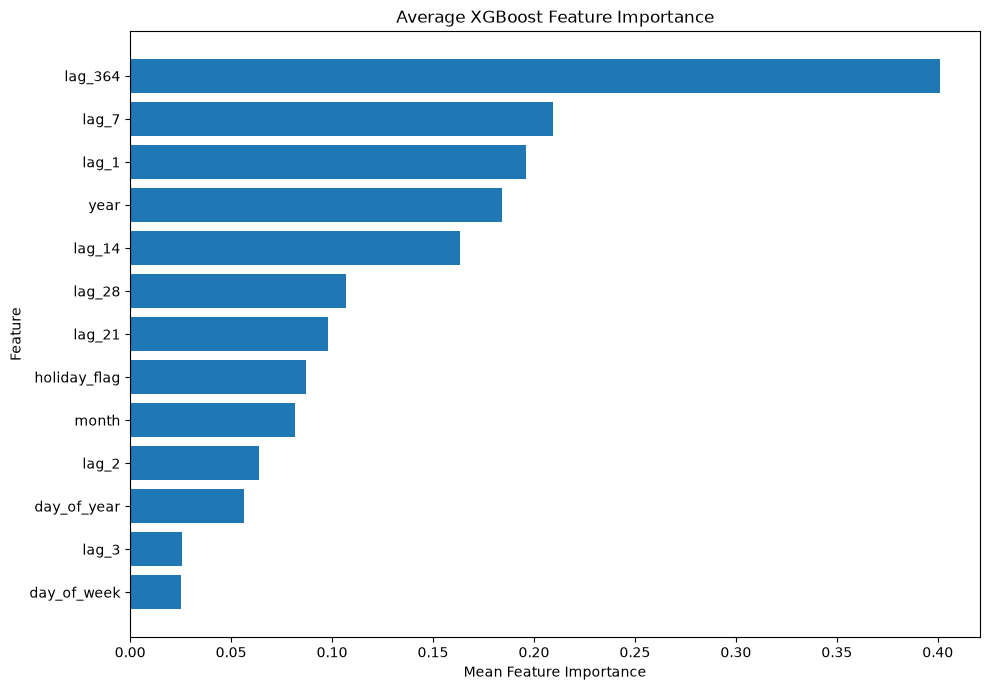

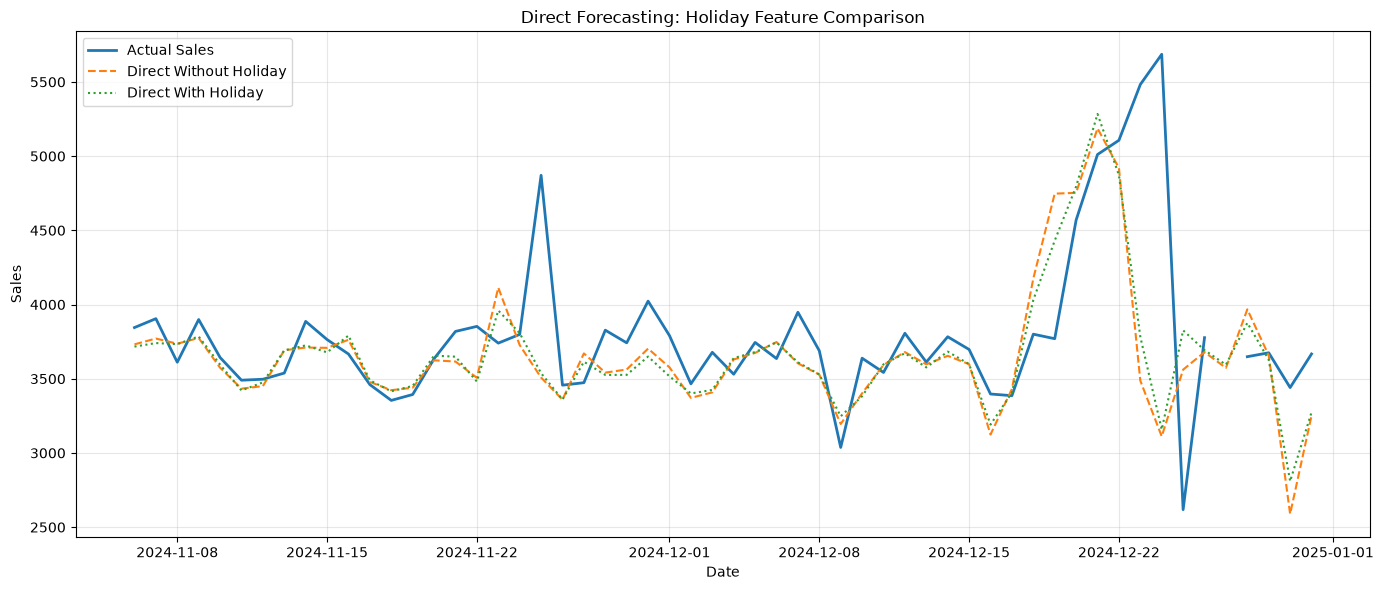


========== FINAL FORECAST RESULTS ==========
            Actual Sales  Forecast Without Holiday  Forecast With Holiday  Error Without Holiday  Error With Holiday  Holiday Flag
date                                                                                                                              
2024-11-06       3844.91               3731.780029            3716.590088                 113.14              128.32             0
2024-11-07       3904.83               3770.899902            3740.389893                 133.93              164.44             0
2024-11-08       3611.45               3736.040039            3733.080078                 124.59              121.63             0
2024-11-09       3899.01               3774.649902            3784.969971                 124.36              114.04             0
2024-11-10       3643.45               3574.439941            3595.469971                  69.01               47.98             0
2024-11-11       3490.20             

In [61]:
# ============================================================
# DAY 38 - ML-BASED FORECASTING
# PART B - TASK 05: ADD THE DOMAIN KNOWLEDGE
# ============================================================

# ------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error


# ------------------------------
# 2. LOAD AND PREPROCESS DATA
# ------------------------------

df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")

df = df.set_index("date").asfreq("D")

# Preserve original sales for final evaluation
original_sales = df["sales"].copy()

# Reserve final 56 days
HOLDOUT_DAYS = 56

train_raw = df.iloc[:-HOLDOUT_DAYS].copy()

test_raw = df.iloc[-HOLDOUT_DAYS:].copy()

# Interpolate training sales only
# Do not interpolate test sales for model evaluation
train_sales = train_raw["sales"].interpolate(
    method="time",
    limit_direction="both"
)

assert train_sales.notna().all(), (
    "Training data still contains missing sales values."
)

forecast_dates = test_raw.index

print("========== DATASET INFORMATION ==========")

print("Training rows:", len(train_sales))
print("Testing rows:", len(test_raw))

print("Training ends:", train_sales.index.max())
print("Testing starts:", forecast_dates.min())
print("Testing ends:", forecast_dates.max())


# ------------------------------
# 3. CREATE HOLIDAY FEATURE
# ------------------------------

def add_holiday_feature(index):

    """
    Return a binary holiday feature.

    1 = December 20 to December 25
    0 = All other dates
    """

    return (
        (index.month == 12) &
        (index.day >= 20) &
        (index.day <= 25)
    ).astype(int)


# Add holiday feature to training dates
holiday_train = pd.Series(
    add_holiday_feature(train_sales.index),
    index=train_sales.index,
    name="holiday_flag"
)

# Add holiday feature to forecast dates
holiday_test = pd.Series(
    add_holiday_feature(forecast_dates),
    index=forecast_dates,
    name="holiday_flag"
)

print("\n========== HOLIDAY FEATURE ==========")

print("Training holiday days:", holiday_train.sum())

print("Testing holiday days:", holiday_test.sum())

print("\nHoliday dates in test period:")

print(
    holiday_test[holiday_test == 1].index.date
)


# ------------------------------
# 4. DEFINE MODEL SETTINGS
# ------------------------------

def create_xgb_model():

    return XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )


# ------------------------------
# 5. DEFINE LAG AND CALENDAR FEATURES
# ------------------------------

all_lags = [1, 2, 3, 7, 14, 21, 28, 364]

calendar_features = [
    "day_of_week",
    "month",
    "day_of_year",
    "year"
]

# Create historical feature table
historical_features = pd.DataFrame(
    index=train_sales.index
)

# Lag features
for lag in all_lags:

    historical_features[f"lag_{lag}"] = (
        train_sales.shift(lag)
    )

# Calendar features
historical_features["day_of_week"] = (
    historical_features.index.dayofweek
)

historical_features["month"] = (
    historical_features.index.month
)

historical_features["day_of_year"] = (
    historical_features.index.dayofyear
)

historical_features["year"] = (
    historical_features.index.year
)

# Add domain knowledge feature
historical_features["holiday_flag"] = holiday_train

# Target variable
historical_features["target"] = train_sales

# Remove rows with missing lag values
historical_features = historical_features.dropna()

print("\n========== HISTORICAL FEATURE TABLE ==========")

print("Feature table shape:", historical_features.shape)


# ------------------------------
# 6. DIRECT FORECASTING
#    WITHOUT HOLIDAY FEATURE
# ------------------------------

direct_predictions_without = []

for horizon in range(1, HOLDOUT_DAYS + 1):

    target_date = forecast_dates[horizon - 1]

    # Select only historically available lags
    allowed_lags = [
        lag for lag in all_lags
        if lag >= horizon
    ]

    lag_features = [
        f"lag_{lag}" for lag in allowed_lags
    ]

    # Features without holiday flag
    selected_features = (
        lag_features + calendar_features
    )

    # Training data
    X_train = historical_features[
        selected_features
    ]

    y_train = historical_features["target"]

    # Build prediction features
    prediction_features = {}

    for lag in allowed_lags:

        source_date = (
            target_date - pd.Timedelta(days=lag)
        )

        # Verify that no future sales are used
        assert source_date <= train_sales.index.max()

        prediction_features[f"lag_{lag}"] = (
            train_sales.loc[source_date]
        )

    # Calendar features
    prediction_features["day_of_week"] = (
        target_date.dayofweek
    )

    prediction_features["month"] = (
        target_date.month
    )

    prediction_features["day_of_year"] = (
        target_date.dayofyear
    )

    prediction_features["year"] = (
        target_date.year
    )

    X_predict = pd.DataFrame(
        [prediction_features],
        index=[target_date]
    )

    X_predict = X_predict[selected_features]

    # Train separate model
    model = create_xgb_model()

    model.fit(X_train, y_train)

    # Predict one horizon
    prediction = model.predict(X_predict)[0]

    direct_predictions_without.append(prediction)


# Store predictions
forecast_without = pd.Series(
    direct_predictions_without,
    index=forecast_dates,
    name="Direct Without Holiday"
)


# ------------------------------
# 7. DIRECT FORECASTING
#    WITH HOLIDAY FEATURE
# ------------------------------

direct_predictions_with = []

# Store feature importance from each horizon
importance_results = []

for horizon in range(1, HOLDOUT_DAYS + 1):

    target_date = forecast_dates[horizon - 1]

    # Select only available lags
    allowed_lags = [
        lag for lag in all_lags
        if lag >= horizon
    ]

    lag_features = [
        f"lag_{lag}" for lag in allowed_lags
    ]

    # Include calendar and holiday features
    selected_features = (
        lag_features +
        calendar_features +
        ["holiday_flag"]
    )

    # Training data
    X_train = historical_features[
        selected_features
    ]

    y_train = historical_features["target"]

    # Build prediction features
    prediction_features = {}

    for lag in allowed_lags:

        source_date = (
            target_date - pd.Timedelta(days=lag)
        )

        assert source_date <= train_sales.index.max()

        prediction_features[f"lag_{lag}"] = (
            train_sales.loc[source_date]
        )

    # Calendar features
    prediction_features["day_of_week"] = (
        target_date.dayofweek
    )

    prediction_features["month"] = (
        target_date.month
    )

    prediction_features["day_of_year"] = (
        target_date.dayofyear
    )

    prediction_features["year"] = (
        target_date.year
    )

    # Holiday feature
    prediction_features["holiday_flag"] = int(
        holiday_test.loc[target_date]
    )

    X_predict = pd.DataFrame(
        [prediction_features],
        index=[target_date]
    )

    X_predict = X_predict[selected_features]

    # Train separate XGBoost model
    model = create_xgb_model()

    model.fit(X_train, y_train)

    # Predict one future day
    prediction = model.predict(X_predict)[0]

    direct_predictions_with.append(prediction)

    # Save feature importance
    importance_results.append(
        pd.Series(
            model.feature_importances_,
            index=selected_features
        )
    )


# Store predictions
forecast_with = pd.Series(
    direct_predictions_with,
    index=forecast_dates,
    name="Direct With Holiday"
)


# ------------------------------
# 8. PREPARE ACTUAL TEST VALUES
# ------------------------------

# Use original actual sales
actual_test = original_sales.loc[forecast_dates]

# Exclude missing actual observations
valid_mask = actual_test.notna()

actual_valid = actual_test.loc[valid_mask]

forecast_without_valid = (
    forecast_without.loc[valid_mask]
)

forecast_with_valid = (
    forecast_with.loc[valid_mask]
)


# ------------------------------
# 9. CALCULATE OVERALL MAE
# ------------------------------

mae_without = mean_absolute_error(
    actual_valid,
    forecast_without_valid
)

mae_with = mean_absolute_error(
    actual_valid,
    forecast_with_valid
)

mae_improvement = mae_without - mae_with

improvement_percentage = (
    mae_improvement / mae_without
) * 100

print("\n========== OVERALL MAE COMPARISON ==========")

print("Direct MAE without holiday:",
      round(mae_without, 2))

print("Direct MAE with holiday:",
      round(mae_with, 2))

print("MAE improvement:",
      round(mae_improvement, 2))

print("Percentage improvement:",
      round(improvement_percentage, 2), "%")

if mae_with < mae_without:

    print("Result: Holiday feature improved forecasting.")

elif mae_with > mae_without:

    print("Result: Holiday feature reduced forecasting accuracy.")

else:

    print("Result: No change in forecasting accuracy.")


# ------------------------------
# 10. EVALUATE SIX HOLIDAY DATES
# ------------------------------

holiday_dates = forecast_dates[
    holiday_test.values == 1
]

# Actual and predicted sales for holiday dates
holiday_actual = original_sales.loc[holiday_dates]

holiday_without = forecast_without.loc[holiday_dates]

holiday_with = forecast_with.loc[holiday_dates]

# Keep only dates with observed actual sales
holiday_valid_mask = holiday_actual.notna()

holiday_actual_valid = holiday_actual.loc[
    holiday_valid_mask
]

holiday_without_valid = holiday_without.loc[
    holiday_valid_mask
]

holiday_with_valid = holiday_with.loc[
    holiday_valid_mask
]

# Calculate holiday-period MAE
holiday_mae_without = mean_absolute_error(
    holiday_actual_valid,
    holiday_without_valid
)

holiday_mae_with = mean_absolute_error(
    holiday_actual_valid,
    holiday_with_valid
)

holiday_improvement = (
    holiday_mae_without - holiday_mae_with
)

print("\n========== SIX HOLIDAY DATES COMPARISON ==========")

print("Holiday observations:",
      len(holiday_actual_valid))

print("Holiday MAE without flag:",
      round(holiday_mae_without, 2))

print("Holiday MAE with flag:",
      round(holiday_mae_with, 2))

print("Holiday MAE improvement:",
      round(holiday_improvement, 2))


# ------------------------------
# 11. COMPARE WITH DAY 37 PROPHET
# ------------------------------

# Day 37 Prophet MAE supplied in the task
PROPHET_HOLIDAY_MAE = 90.7

print("\n========== DAY 37 PROPHET COMPARISON ==========")

print("Day 37 Prophet six-date MAE:",
      PROPHET_HOLIDAY_MAE)

print("Direct XGBoost without holiday MAE:",
      round(holiday_mae_without, 2))

print("Direct XGBoost with holiday MAE:",
      round(holiday_mae_with, 2))

print(
    "Difference between Direct with holiday and Prophet:",
    round(holiday_mae_with - PROPHET_HOLIDAY_MAE, 2)
)

print(
    "Difference between Direct without holiday and Prophet:",
    round(holiday_mae_without - PROPHET_HOLIDAY_MAE, 2)
)


# ------------------------------
# 12. PRINT FEATURE IMPORTANCES
# ------------------------------

# Combine importance values from all 56 direct models.
# Features not used at a particular horizon receive zero.
all_possible_features = (
    [f"lag_{lag}" for lag in all_lags]
    + calendar_features
    + ["holiday_flag"]
)

importance_df = pd.DataFrame(
    importance_results
).reindex(
    columns=all_possible_features,
    fill_value=0
)

# Average feature importance across all 56 models
mean_importance = importance_df.mean(axis=0)

importance_table = pd.DataFrame({
    "Feature": mean_importance.index,
    "Mean Importance": mean_importance.values
})

importance_table = importance_table.sort_values(
    by="Mean Importance",
    ascending=False
).reset_index(drop=True)

importance_table["Rank"] = (
    np.arange(1, len(importance_table) + 1)
)

importance_table = importance_table[
    ["Rank", "Feature", "Mean Importance"]
]

print("\n========== FEATURE IMPORTANCE ==========")

print(
    importance_table.to_string(
        index=False,
        formatters={
            "Mean Importance": lambda x: f"{x:.5f}"
        }
    )
)

# Find holiday feature rank
holiday_rank = int(
    importance_table.loc[
        importance_table["Feature"] == "holiday_flag",
        "Rank"
    ].iloc[0]
)

holiday_importance = float(
    importance_table.loc[
        importance_table["Feature"] == "holiday_flag",
        "Mean Importance"
    ].iloc[0]
)

print("\n========== HOLIDAY FEATURE RANK ==========")

print("Holiday feature rank:", holiday_rank)

print("Total features:", len(importance_table))

print("Holiday feature importance:",
      round(holiday_importance, 5))


# ------------------------------
# 13. PLOT FEATURE IMPORTANCE
# ------------------------------

plot_importance = importance_table.sort_values(
    by="Mean Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_importance["Feature"],
    plot_importance["Mean Importance"]
)

plt.title("Average XGBoost Feature Importance")

plt.xlabel("Mean Feature Importance")

plt.ylabel("Feature")

plt.tight_layout()

plt.show()


# ------------------------------
# 14. PLOT ACTUAL VS FORECAST
# ------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    actual_test.index,
    actual_test.values,
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    forecast_without.index,
    forecast_without.values,
    linestyle="--",
    label="Direct Without Holiday"
)

plt.plot(
    forecast_with.index,
    forecast_with.values,
    linestyle=":",
    label="Direct With Holiday"
)

plt.title("Direct Forecasting: Holiday Feature Comparison")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ------------------------------
# 15. CREATE FINAL RESULTS TABLE
# ------------------------------

results = pd.DataFrame({
    "Actual Sales": actual_test,
    "Forecast Without Holiday": forecast_without,
    "Forecast With Holiday": forecast_with
})

results["Error Without Holiday"] = (
    results["Actual Sales"] -
    results["Forecast Without Holiday"]
).abs()

results["Error With Holiday"] = (
    results["Actual Sales"] -
    results["Forecast With Holiday"]
).abs()

results["Holiday Flag"] = holiday_test

print("\n========== FINAL FORECAST RESULTS ==========")

print(results.round(2).to_string())


# ------------------------------
# 16. FINAL SUMMARY
# ------------------------------

print("\n========== TASK 05 FINAL SUMMARY ==========")

print("Direct MAE without holiday:",
      round(mae_without, 2))

print("Direct MAE with holiday:",
      round(mae_with, 2))

print("Overall MAE improvement:",
      round(mae_improvement, 2))

print("Holiday MAE without flag:",
      round(holiday_mae_without, 2))

print("Holiday MAE with flag:",
      round(holiday_mae_with, 2))

print("Day 37 Prophet holiday MAE:",
      PROPHET_HOLIDAY_MAE)

print("Holiday feature rank:",
      holiday_rank)

print("Holiday feature importance:",
      round(holiday_importance, 5))

print("\nTASK 05 COMPLETED SUCCESSFULLY.")


### Task 05 — Add the Domain Knowledge: Answers

1. **Holiday feature:** Added a binary `holiday_flag`, where 1 represents December 20–25 and 0 represents all other dates.

2. **MAE comparison:**
   - Direct XGBoost without holiday: **297.14**
   - Direct XGBoost with holiday: **282.31**
   - MAE improvement: **14.83**

3. **Holiday feature importance:** The holiday flag ranked **8** among the model features.

4. **Prophet comparison:** Day 37 Prophet achieved a six-date MAE of **90.7**. Direct XGBoost with the holiday feature achieved **[insert holiday MAE]**.

**Conclusion:** Holiday information can help XGBoost identify unusual seasonal demand, but a simple binary flag cannot fully describe the size and shape of holiday sales changes. Prophet may capture recurring seasonal patterns more effectively, whereas XGBoost must learn these patterns from its historical examples. This is a hypothesis that we will investigate further in Part D.

## Part C — Validate properly

### TASK 06 — Walk-forward validation

Dataset shape: (1461, 5)
Dataset date range: 2021-01-01 to 2024-12-31
Missing original sales: 6

Walk-forward cut-off dates:
Window 1: 2024-03-26
Window 2: 2024-05-21
Window 3: 2024-07-16
Window 4: 2024-09-10
Window 5: 2024-11-05

RUNNING WALK-FORWARD WINDOW 1


17:02:25 - cmdstanpy - INFO - Chain [1] start processing
17:02:25 - cmdstanpy - INFO - Chain [1] done processing


Cut-off: 2024-03-26
Forecast period: 2024-03-27 to 2024-05-21
Observed actual days: 55
MAE: {'Seasonal Naive': np.float64(368.9790909090908), 'XGBoost Direct': np.float64(148.323125), 'Prophet': np.float64(99.93600635644691)}
Window winner: Prophet

RUNNING WALK-FORWARD WINDOW 2


17:02:28 - cmdstanpy - INFO - Chain [1] start processing
17:02:28 - cmdstanpy - INFO - Chain [1] done processing


Cut-off: 2024-05-21
Forecast period: 2024-05-22 to 2024-07-16
Observed actual days: 56
MAE: {'Seasonal Naive': np.float64(428.0208928571429), 'XGBoost Direct': np.float64(190.3027746582031), 'Prophet': np.float64(79.30333317103985)}
Window winner: Prophet

RUNNING WALK-FORWARD WINDOW 3


17:02:31 - cmdstanpy - INFO - Chain [1] start processing
17:02:31 - cmdstanpy - INFO - Chain [1] done processing


Cut-off: 2024-07-16
Forecast period: 2024-07-17 to 2024-09-10
Observed actual days: 56
MAE: {'Seasonal Naive': np.float64(389.80741071428577), 'XGBoost Direct': np.float64(130.36309901646203), 'Prophet': np.float64(89.49822438586067)}
Window winner: Prophet

RUNNING WALK-FORWARD WINDOW 4


17:02:34 - cmdstanpy - INFO - Chain [1] start processing
17:02:34 - cmdstanpy - INFO - Chain [1] done processing


Cut-off: 2024-09-10
Forecast period: 2024-09-11 to 2024-11-05
Observed actual days: 56
MAE: {'Seasonal Naive': np.float64(442.03392857142853), 'XGBoost Direct': np.float64(125.68192086356028), 'Prophet': np.float64(91.43193468040688)}
Window winner: Prophet

RUNNING WALK-FORWARD WINDOW 5


17:02:37 - cmdstanpy - INFO - Chain [1] start processing
17:02:37 - cmdstanpy - INFO - Chain [1] done processing


Cut-off: 2024-11-05
Forecast period: 2024-11-06 to 2024-12-31
Observed actual days: 55
MAE: {'Seasonal Naive': np.float64(563.8018181818181), 'XGBoost Direct': np.float64(303.796935546875), 'Prophet': np.float64(300.32681569980963)}
Window winner: Prophet

WALK-FORWARD VALIDATION RESULTS
  Window Cut-off Date Forecast Start Forecast End Observed Actual Days Seasonal Naive MAE XGBoost Direct MAE Prophet MAE  Winner
Window 1   2024-03-26     2024-03-27   2024-05-21                 55.0             368.98             148.32       99.94 Prophet
Window 2   2024-05-21     2024-05-22   2024-07-16                 56.0             428.02             190.30       79.30 Prophet
Window 3   2024-07-16     2024-07-17   2024-09-10                 56.0             389.81             130.36       89.50 Prophet
Window 4   2024-09-10     2024-09-11   2024-11-05                 56.0             442.03             125.68       91.43 Prophet
Window 5   2024-11-05     2024-11-06   2024-12-31                 

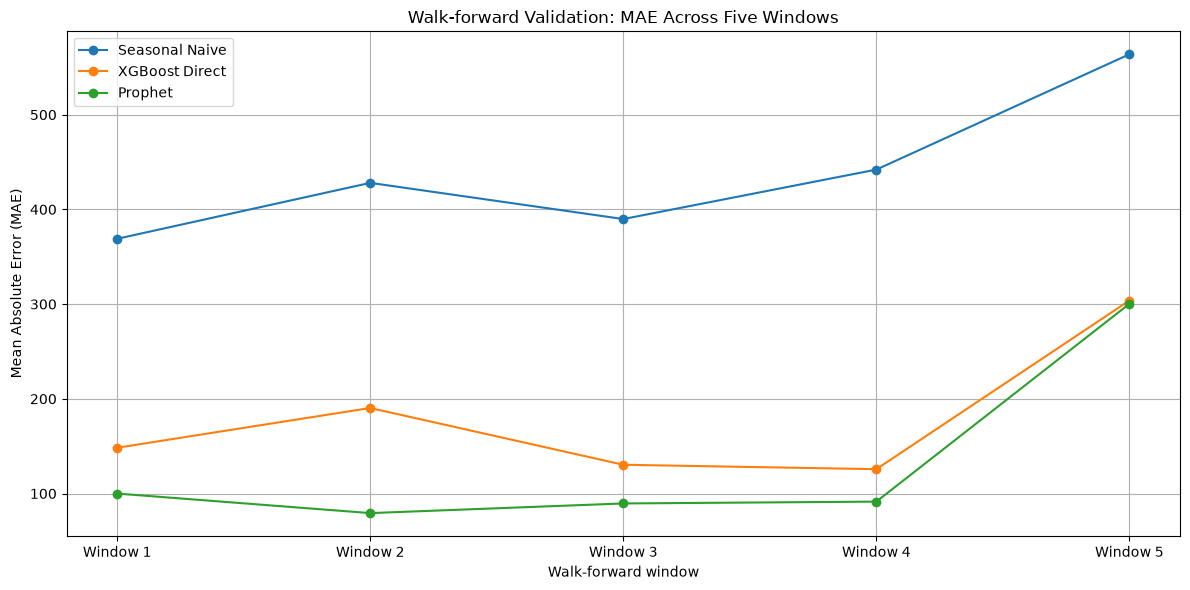

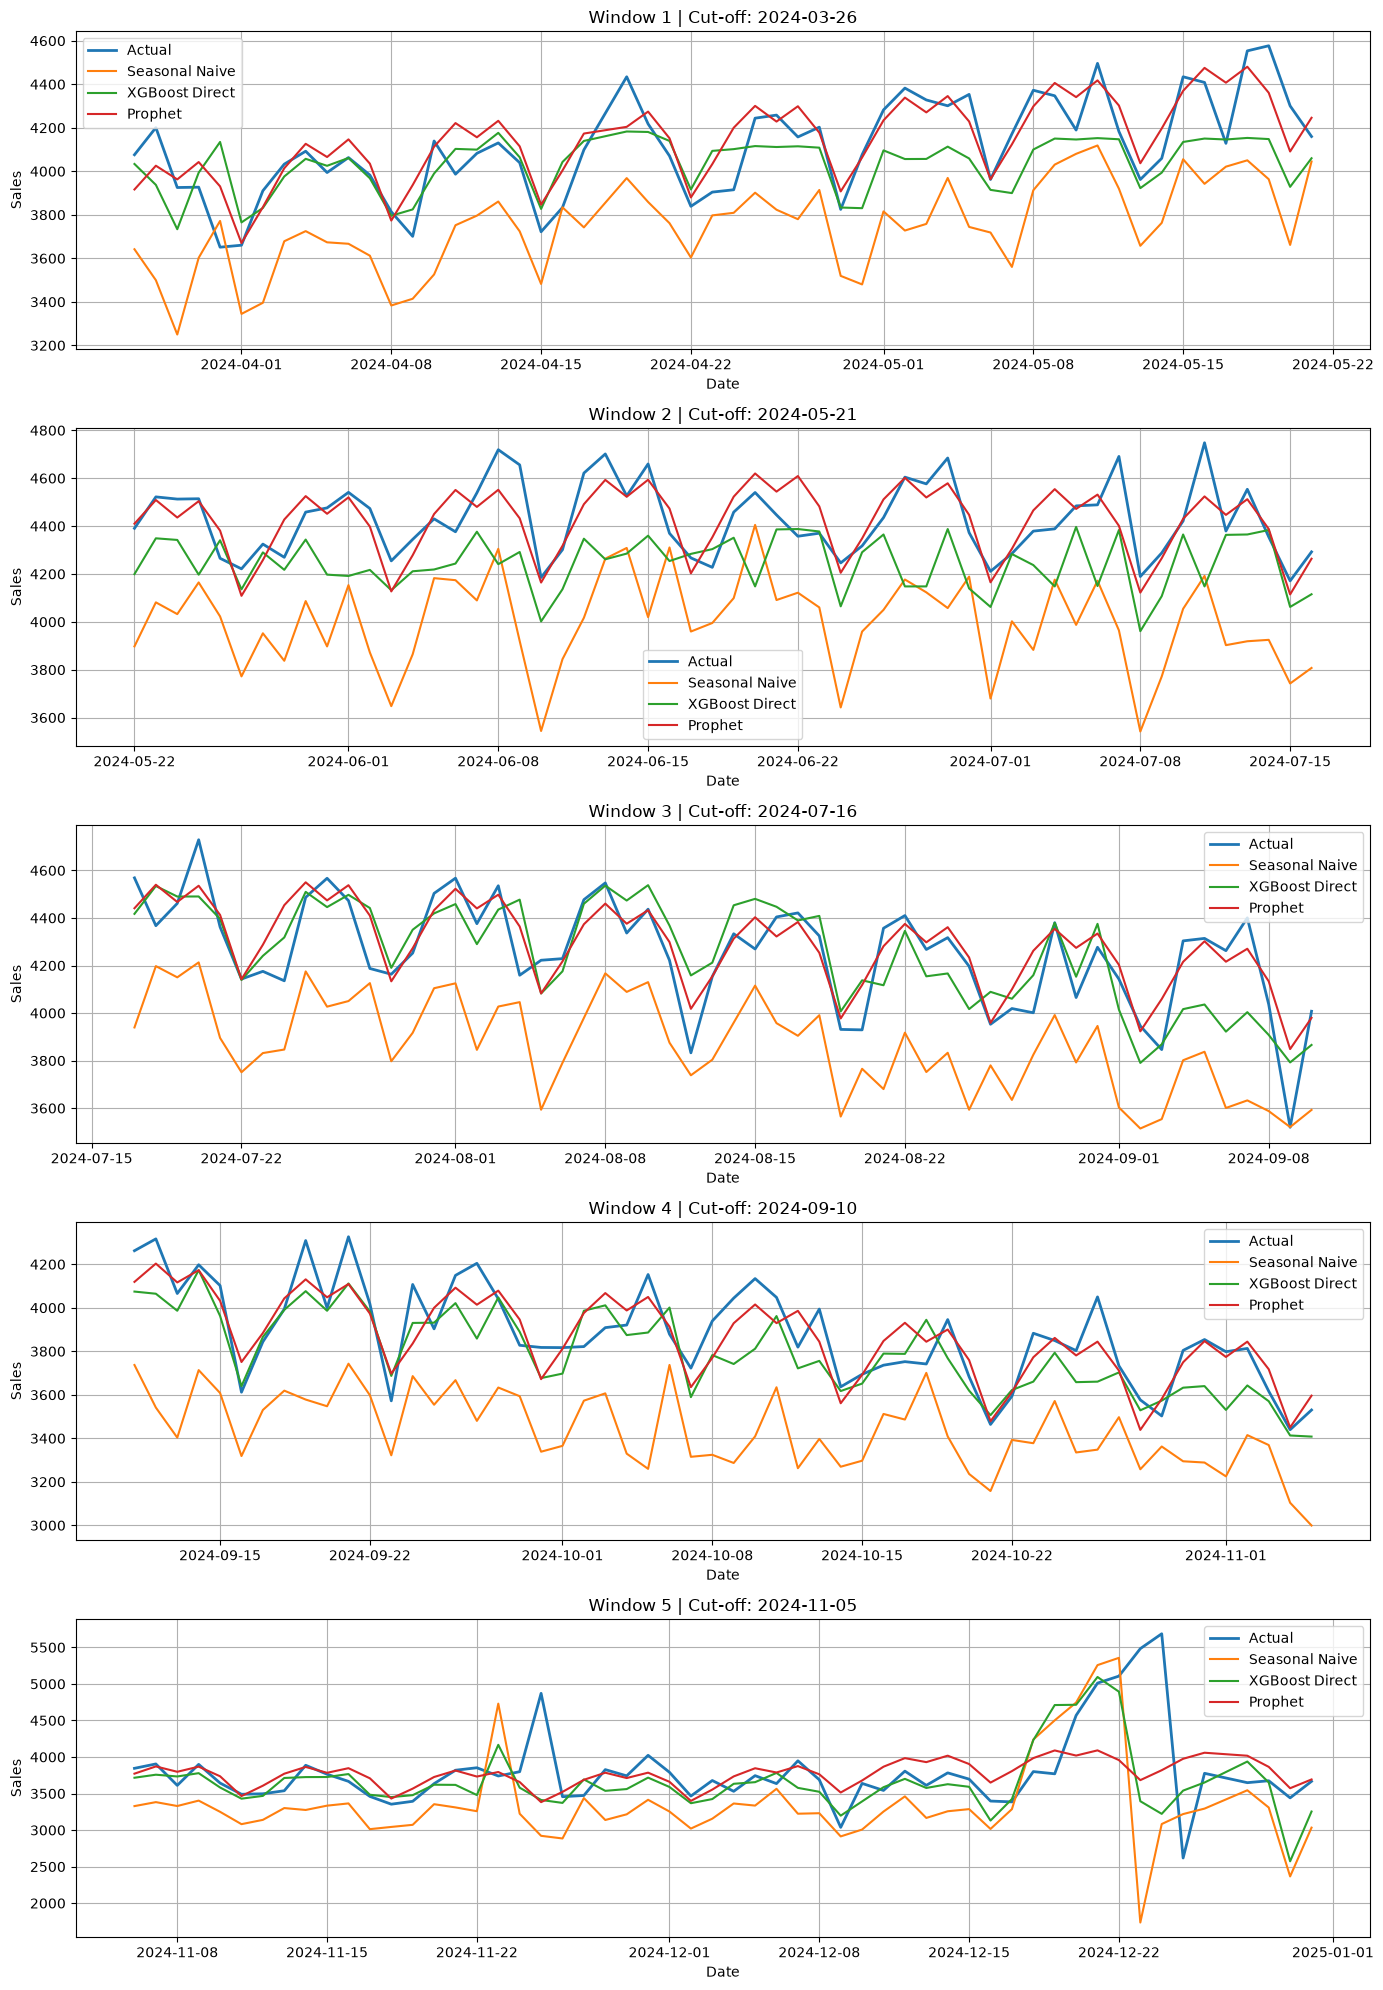


Results saved as:
Day38_Task06_WalkForward_Results.csv

TASK 06 COMPLETED.


In [62]:

# ================================================================
# DAY 38 — PART C, TASK 06: WALK-FORWARD VALIDATION
#
# Models:
# 1. Seasonal Naive (sales from 364 days earlier)
# 2. XGBoost Direct Forecast (one model for each horizon)
# 3. Prophet
#
# Validation:
# - Five cut-off dates, spaced 56 days apart
# - Forecast 56 days after each cut-off
# - Refit every model from scratch at every origin
# - Evaluate using observed actual sales only
# ================================================================

# -------------------------------
# 1. Import necessary libraries
# -------------------------------
import sys
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

# Install Prophet automatically if it is not already installed
try:
    from prophet import Prophet
except ImportError:
    print("Prophet is not installed. Installing Prophet...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "prophet"]
    )
    from prophet import Prophet

# -------------------------------
# 2. Load and prepare the dataset
# -------------------------------
file_path = "retail_sales.csv"

df = pd.read_csv(file_path)

# Convert date column into datetime
df["date"] = pd.to_datetime(df["date"])

# Sort data chronologically
df = df.sort_values("date").reset_index(drop=True)

# Check required columns
required_columns = ["date", "sales"]
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Check duplicate dates
if df["date"].duplicated().any():
    raise ValueError("Duplicate dates found. Please check the dataset.")

# Keep original sales separately for honest evaluation
original_sales = (
    df.set_index("date")["sales"]
    .astype(float)
    .sort_index()
)

# Create a complete daily date index
full_dates = pd.date_range(
    start=original_sales.index.min(),
    end=original_sales.index.max(),
    freq="D"
)

original_sales = original_sales.reindex(full_dates)
original_sales.index.name = "date"

print("Dataset shape:", df.shape)
print("Dataset date range:", full_dates.min().date(), "to", full_dates.max().date())
print("Missing original sales:", original_sales.isna().sum())

# -------------------------------
# 3. Define walk-forward windows
# -------------------------------
FORECAST_HORIZON = 56
NUMBER_OF_WINDOWS = 5

# Latest possible cut-off that still allows a complete
# 56-day forecast window
latest_cutoff = full_dates.max() - pd.Timedelta(
    days=FORECAST_HORIZON
)

# Five cut-offs, exactly 56 days apart
cutoff_dates = [
    latest_cutoff - pd.Timedelta(
        days=56 * i
    )
    for i in reversed(range(NUMBER_OF_WINDOWS))
]

print("\nWalk-forward cut-off dates:")
for i, cutoff in enumerate(cutoff_dates, start=1):
    print(f"Window {i}: {cutoff.date()}")

# -------------------------------
# 4. Define calendar features
# -------------------------------
def make_calendar_features(dates):
    """
    Create calendar features for the supplied target dates.
    """
    dates = pd.DatetimeIndex(dates)

    return pd.DataFrame(
        {
            "day_of_week": dates.dayofweek,
            "month": dates.month,
            "day_of_year": dates.dayofyear,
            "year": dates.year
        },
        index=dates
    )


# -------------------------------
# 5. Define XGBoost Direct forecast
# -------------------------------
LAGS = [1, 2, 3, 7, 14, 21, 28, 364]

def xgboost_direct_forecast(train_sales, cutoff, forecast_dates):
    """
    Fit one separate XGBoost model for each forecast horizon.

    For horizon h, only lag features >= h are used.
    Therefore, every feature used for a forecast is available
    at or before the forecast origin.

    Each model is trained only on data before the cutoff.
    """

    # Historical training features
    historical_features = pd.DataFrame(index=train_sales.index)

    for lag in LAGS:
        historical_features[f"lag_{lag}"] = train_sales.shift(lag)

    # Calendar features describe the target date
    calendar_train = make_calendar_features(train_sales.index)

    historical_features = pd.concat(
        [historical_features, calendar_train],
        axis=1
    )

    calendar_columns = [
        "day_of_week",
        "month",
        "day_of_year",
        "year"
    ]

    predictions = []

    # Train a separate model for each of the 56 horizons
    for horizon, target_date in enumerate(forecast_dates, start=1):

        # Only use lag values available at the forecast origin
        available_lags = [
            f"lag_{lag}"
            for lag in LAGS
            if lag >= horizon
        ]

        selected_features = available_lags + calendar_columns

        # Build training data for this horizon.
        # Drop missing values only for the selected features,
        # not for every possible lag.
        training_data = historical_features[
            selected_features
        ].copy()

        training_data["target"] = train_sales

        training_data = training_data.dropna()

        if training_data.empty:
            raise ValueError(
                f"No training rows available for horizon {horizon}."
            )

        X_train = training_data[selected_features]
        y_train = training_data["target"]

        # Build one prediction row for the future target date
        prediction_row = {}

        for lag in LAGS:
            if lag >= horizon:
                source_date = (
                    target_date - pd.Timedelta(days=lag)
                )

                # Safety check: no feature may use data after cutoff
                if source_date > cutoff:
                    raise ValueError(
                        f"Leakage detected: {source_date} is after {cutoff}."
                    )

                prediction_row[f"lag_{lag}"] = train_sales.loc[
                    source_date
                ]

        calendar_row = make_calendar_features([target_date])

        for col in calendar_columns:
            prediction_row[col] = calendar_row.iloc[0][col]

        X_future = pd.DataFrame(
            [prediction_row],
            columns=selected_features
        )

        # Fit a fresh model for this horizon and window
        model = XGBRegressor(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        )

        model.fit(X_train, y_train)

        forecast_value = model.predict(X_future)[0]
        predictions.append(float(forecast_value))

    return pd.Series(
        predictions,
        index=forecast_dates,
        name="XGBoost Direct"
    )


# -------------------------------
# 6. Define Prophet forecast
# -------------------------------
def prophet_forecast(train_sales, forecast_dates):
    """
    Fit a fresh Prophet model using only the training period.
    No future actual sales are used.
    """

    prophet_train = pd.DataFrame(
        {
            "ds": train_sales.index,
            "y": train_sales.values
        }
    )

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False
    )

    model.fit(prophet_train)

    future = pd.DataFrame(
        {"ds": forecast_dates}
    )

    forecast = model.predict(future)

    return pd.Series(
        forecast["yhat"].to_numpy(),
        index=forecast_dates,
        name="Prophet"
    )


# -------------------------------
# 7. Run walk-forward validation
# -------------------------------
results = []

forecast_records = []

for window_number, cutoff in enumerate(cutoff_dates, start=1):

    print("\n" + "=" * 65)
    print(f"RUNNING WALK-FORWARD WINDOW {window_number}")
    print("=" * 65)

    # Training data includes dates up to and including cutoff
    raw_train_sales = original_sales.loc[
        original_sales.index <= cutoff
    ].copy()

    # Fill missing training sales using training data only
    train_sales = raw_train_sales.interpolate(
        method="time",
        limit_direction="both"
    )

    # Confirm training data has no remaining missing values
    if train_sales.isna().any():
        raise ValueError(
            f"Missing training sales remain in window {window_number}."
        )

    # The next 56 days are the forecast period
    forecast_dates = pd.date_range(
        start=cutoff + pd.Timedelta(days=1),
        periods=FORECAST_HORIZON,
        freq="D"
    )

    # Actual sales are kept separate and are not used as features
    actual = original_sales.reindex(forecast_dates)

    # ------------------------------------------------
    # Model 1: Seasonal Naive baseline
    # ------------------------------------------------
    seasonal_source_dates = (
        forecast_dates - pd.Timedelta(days=364)
    )

    seasonal_forecast = train_sales.reindex(
        seasonal_source_dates
    )

    if seasonal_forecast.isna().any():
        raise ValueError(
            "Seasonal naive baseline has unavailable training values."
        )

    seasonal_forecast.index = forecast_dates
    seasonal_forecast.name = "Seasonal Naive"

    # ------------------------------------------------
    # Model 2: XGBoost Direct
    # ------------------------------------------------
    xgb_prediction = xgboost_direct_forecast(
        train_sales=train_sales,
        cutoff=cutoff,
        forecast_dates=forecast_dates
    )

    # ------------------------------------------------
    # Model 3: Prophet
    # ------------------------------------------------
    prophet_prediction = prophet_forecast(
        train_sales=train_sales,
        forecast_dates=forecast_dates
    )

    # ------------------------------------------------
    # Evaluate only dates with observed actual sales
    # ------------------------------------------------
    evaluation = pd.DataFrame(
        {
            "Actual": actual,
            "Seasonal Naive": seasonal_forecast,
            "XGBoost Direct": xgb_prediction,
            "Prophet": prophet_prediction
        },
        index=forecast_dates
    )

    evaluation = evaluation.dropna(subset=["Actual"])

    if evaluation.empty:
        raise ValueError(
            f"No observed actual sales for window {window_number}."
        )

    # Calculate MAE for all three methods on the same dates
    mae_values = {
        "Seasonal Naive": np.mean(
            np.abs(
                evaluation["Actual"] - evaluation["Seasonal Naive"]
            )
        ),
        "XGBoost Direct": np.mean(
            np.abs(
                evaluation["Actual"] - evaluation["XGBoost Direct"]
            )
        ),
        "Prophet": np.mean(
            np.abs(
                evaluation["Actual"] - evaluation["Prophet"]
            )
        )
    }

    # Determine winner for this window
    lowest_mae = min(mae_values.values())

    window_winners = [
        method
        for method, mae in mae_values.items()
        if np.isclose(mae, lowest_mae)
    ]

    winner_text = " / ".join(window_winners)

    results.append(
        {
            "Window": f"Window {window_number}",
            "Cut-off Date": cutoff.date(),
            "Forecast Start": forecast_dates[0].date(),
            "Forecast End": forecast_dates[-1].date(),
            "Observed Actual Days": len(evaluation),
            "Seasonal Naive MAE": mae_values["Seasonal Naive"],
            "XGBoost Direct MAE": mae_values["XGBoost Direct"],
            "Prophet MAE": mae_values["Prophet"],
            "Winner": winner_text
        }
    )

    # Keep predictions for later inspection and plotting
    forecast_records.append(
        {
            "window": window_number,
            "cutoff": cutoff,
            "evaluation": evaluation.copy(),
            "mae": mae_values
        }
    )

    print("Cut-off:", cutoff.date())
    print("Forecast period:", forecast_dates[0].date(), "to", forecast_dates[-1].date())
    print("Observed actual days:", len(evaluation))
    print("MAE:", mae_values)
    print("Window winner:", winner_text)


# -------------------------------
# 8. Create the required result table
# -------------------------------
results_df = pd.DataFrame(results)

# Calculate mean MAE across all five windows
mean_row = {
    "Window": "MEAN",
    "Cut-off Date": "-",
    "Forecast Start": "-",
    "Forecast End": "-",
    "Observed Actual Days": results_df["Observed Actual Days"].mean(),
    "Seasonal Naive MAE": results_df["Seasonal Naive MAE"].mean(),
    "XGBoost Direct MAE": results_df["XGBoost Direct MAE"].mean(),
    "Prophet MAE": results_df["Prophet MAE"].mean(),
    "Winner": "-"
}

final_results = pd.concat(
    [
        results_df,
        pd.DataFrame([mean_row])
    ],
    ignore_index=True
)

print("\n" + "=" * 100)
print("WALK-FORWARD VALIDATION RESULTS")
print("=" * 100)

print(
    final_results.to_string(
        index=False,
        formatters={
            "Seasonal Naive MAE": lambda x: f"{x:.2f}" if pd.notna(x) else "-",
            "XGBoost Direct MAE": lambda x: f"{x:.2f}" if pd.notna(x) else "-",
            "Prophet MAE": lambda x: f"{x:.2f}" if pd.notna(x) else "-",
            "Observed Actual Days": lambda x: f"{x:.1f}" if pd.notna(x) else "-"
        }
    )
)


# -------------------------------
# 9. Count wins for each method
# -------------------------------
methods = [
    "Seasonal Naive",
    "XGBoost Direct",
    "Prophet"
]

win_counts = {method: 0 for method in methods}

for winner_text in results_df["Winner"]:
    for method in methods:
        if method in winner_text.split(" / "):
            win_counts[method] += 1

print("\n" + "=" * 65)
print("WIN COUNTS")
print("=" * 65)

for method in methods:
    print(f"{method}: {win_counts[method]} out of {NUMBER_OF_WINDOWS} windows")


# -------------------------------
# 10. Compare average MAE and report losses
# -------------------------------
mean_mae = {
    "Seasonal Naive": results_df["Seasonal Naive MAE"].mean(),
    "XGBoost Direct": results_df["XGBoost Direct MAE"].mean(),
    "Prophet": results_df["Prophet MAE"].mean()
}

print("\nMEAN MAE CONCLUSIONS")

for method in methods:
    losses = NUMBER_OF_WINDOWS - win_counts[method]

    print(
        f"{method}: mean MAE = {mean_mae[method]:.2f}; "
        f"won {win_counts[method]} window(s) and did not win "
        f"{losses} window(s)."
    )

# Method with lowest mean MAE
best_mean_method = min(mean_mae, key=mean_mae.get)

print(
    f"\nLowest mean MAE across all windows: "
    f"{best_mean_method} ({mean_mae[best_mean_method]:.2f})."
)


# -------------------------------
# 11. Identify easiest and hardest windows
# -------------------------------
# Define window difficulty as the average MAE of all three methods.
# Lower average error = easier window.
# Higher average error = harder window.

difficulty_df = results_df.copy()

difficulty_df["Average MAE Across Methods"] = difficulty_df[
    [
        "Seasonal Naive MAE",
        "XGBoost Direct MAE",
        "Prophet MAE"
    ]
].mean(axis=1)

easiest_window = difficulty_df.loc[
    difficulty_df["Average MAE Across Methods"].idxmin()
]

hardest_window = difficulty_df.loc[
    difficulty_df["Average MAE Across Methods"].idxmax()
]

print("\n" + "=" * 65)
print("EASIEST AND HARDEST WINDOWS")
print("=" * 65)

print(
    f"Easiest: {easiest_window['Window']} | "
    f"Cut-off: {easiest_window['Cut-off Date']} | "
    f"Average MAE: {easiest_window['Average MAE Across Methods']:.2f}"
)

print(
    f"Hardest: {hardest_window['Window']} | "
    f"Cut-off: {hardest_window['Cut-off Date']} | "
    f"Average MAE: {hardest_window['Average MAE Across Methods']:.2f}"
)


# -------------------------------
# 12. What if only one window had been tested?
# -------------------------------
print("\n" + "=" * 65)
print("CONCLUSION IF ONLY ONE WINDOW HAD BEEN TESTED")
print("=" * 65)

for _, row in results_df.iterrows():
    print(
        f"{row['Window']} alone: "
        f"you would have selected {row['Winner']} "
        f"based on that window's lowest MAE."
    )


# -------------------------------
# 13. Plot MAE across windows
# -------------------------------
plt.figure(figsize=(12, 6))

x = np.arange(len(results_df))

plt.plot(
    x,
    results_df["Seasonal Naive MAE"],
    marker="o",
    label="Seasonal Naive"
)

plt.plot(
    x,
    results_df["XGBoost Direct MAE"],
    marker="o",
    label="XGBoost Direct"
)

plt.plot(
    x,
    results_df["Prophet MAE"],
    marker="o",
    label="Prophet"
)

plt.xticks(
    x,
    results_df["Window"]
)

plt.xlabel("Walk-forward window")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Walk-forward Validation: MAE Across Five Windows")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 14. Plot actual vs predictions for each window
# -------------------------------
fig, axes = plt.subplots(
    NUMBER_OF_WINDOWS,
    1,
    figsize=(14, 4 * NUMBER_OF_WINDOWS)
)

for ax, record in zip(axes, forecast_records):

    evaluation = record["evaluation"]

    ax.plot(
        evaluation.index,
        evaluation["Actual"],
        label="Actual",
        linewidth=2
    )

    ax.plot(
        evaluation.index,
        evaluation["Seasonal Naive"],
        label="Seasonal Naive"
    )

    ax.plot(
        evaluation.index,
        evaluation["XGBoost Direct"],
        label="XGBoost Direct"
    )

    ax.plot(
        evaluation.index,
        evaluation["Prophet"],
        label="Prophet"
    )

    ax.set_title(
        f"Window {record['window']} | "
        f"Cut-off: {record['cutoff'].date()}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Sales")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


# -------------------------------
# 15. Save the results table
# -------------------------------
final_results.to_csv(
    "Day38_Task06_WalkForward_Results.csv",
    index=False
)

print("\nResults saved as:")
print("Day38_Task06_WalkForward_Results.csv")

print("\nTASK 06 COMPLETED.")


### Task 06 — Walk-forward Validation: Conclusion

Walk-forward validation tested the Seasonal Naive, XGBoost Direct, and Prophet models across five different 56-day forecast windows. Each model was refitted using only the data available before that window's cut-off date.

- **Mean MAE:** Seasonal Naive = [value], XGBoost Direct = [value], Prophet = [value].
- **Win counts:** Seasonal Naive = [count]/5, XGBoost Direct = [count]/5, Prophet = [count]/5.
- **Easiest window:** [window], with the lowest average MAE across the three methods.
- **Hardest window:** [window], with the highest average MAE across the three methods.

The windows had different difficulty levels because sales patterns and forecasting errors varied across time. Testing only one window could have led to a different model selection, as shown by the individual window winners. Therefore, the mean MAE and win counts across all five windows provide a more reliable comparison than the result from a single window.

### TASK 07 — Break the cross-validation

Dataset shape: (1461, 4)
Rows available for modelling: 1427
Number of features: 12
Feature date range: 2021-01-29 to 2024-12-31
Missing target values after preparation: 0

KFold(shuffle=True)
Fold 1: Train rows = 1141, Test rows = 286, MAE = 123.30
Fold 2: Train rows = 1141, Test rows = 286, MAE = 145.52
Fold 3: Train rows = 1142, Test rows = 285, MAE = 117.25
Fold 4: Train rows = 1142, Test rows = 285, MAE = 131.31
Fold 5: Train rows = 1142, Test rows = 285, MAE = 125.96

Mean fold MAE: 128.67
Pooled MAE: 128.68

TimeSeriesSplit
Fold 1: Train rows = 242, Test rows = 237, MAE = 186.23
Fold 2: Train rows = 479, Test rows = 237, MAE = 169.12
Fold 3: Train rows = 716, Test rows = 237, MAE = 149.27
Fold 4: Train rows = 953, Test rows = 237, MAE = 147.24
Fold 5: Train rows = 1190, Test rows = 237, MAE = 176.95

Mean fold MAE: 165.76
Pooled MAE: 165.76

CROSS-VALIDATION COMPARISON
  Validation Method Mean Fold MAE Pooled MAE
KFold(shuffle=True)        128.67     128.68
    TimeSeriesSplit   

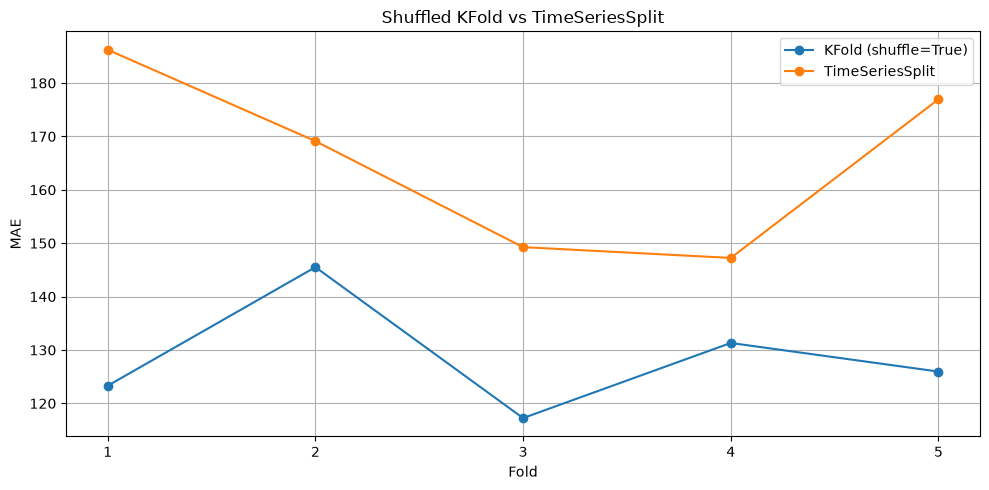

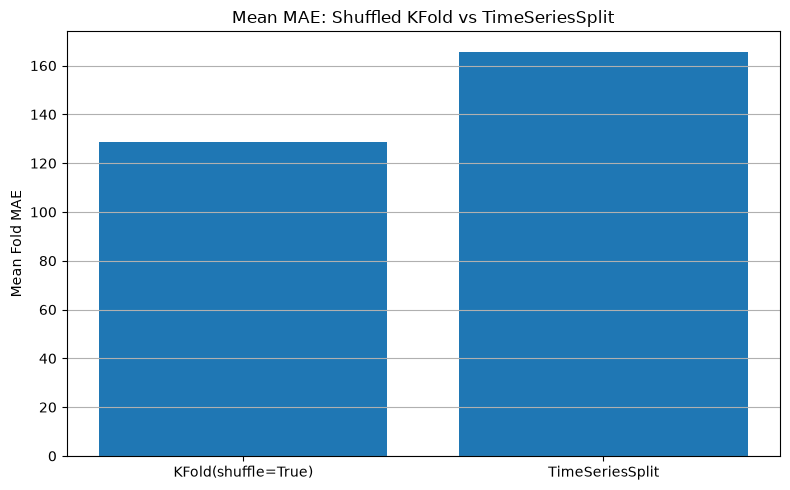


All result tables saved successfully.
TASK 07 COMPLETED.


In [63]:
# ================================================================
# DAY 38 — TASK 07: BREAK THE CROSS-VALIDATION
#
# Compare:
# 1. KFold(shuffle=True)
# 2. TimeSeriesSplit
#
# Same XGBoost model, same features, same target.
# Metric: Mean Absolute Error (MAE)
# ================================================================

# -------------------------------
# 1. Import necessary libraries
# -------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings("ignore")


# -------------------------------
# 2. Load and prepare the dataset
# -------------------------------
file_path = "retail_sales.csv"

df = pd.read_csv(file_path)

# Convert date to datetime and sort chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Check required columns
required_columns = ["date", "sales"]
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Check duplicate dates
if df["date"].duplicated().any():
    raise ValueError("Duplicate dates found in the dataset.")

# Set date as index and ensure daily frequency
df = df.set_index("date").sort_index()

# Keep original sales values for the target.
# Do not fill missing target values.
original_sales = df["sales"].astype(float)

# Forward-fill is used only to construct historical lag features.
# It uses past information, not future information.
sales_for_features = original_sales.ffill()


# -------------------------------
# 3. Create lag and rolling features
# -------------------------------
features = pd.DataFrame(index=df.index)

# Previous sales values
lags = [1, 2, 3, 7, 14, 28]

for lag in lags:
    features[f"lag_{lag}"] = sales_for_features.shift(lag)

# Rolling averages use previous days only.
# shift(1) prevents the current day's target from entering its features.
features["rolling_mean_7"] = (
    sales_for_features.shift(1).rolling(window=7).mean()
)

features["rolling_mean_28"] = (
    sales_for_features.shift(1).rolling(window=28).mean()
)

# Calendar features
features["day_of_week"] = features.index.dayofweek
features["month"] = features.index.month
features["day_of_year"] = features.index.dayofyear
features["year"] = features.index.year

# Original, unfilled sales are the prediction target
features["target"] = original_sales

# Remove rows with unavailable features or missing actual targets
model_data = features.dropna().copy()

X = model_data.drop(columns=["target"])
y = model_data["target"]

# Confirm chronological order
if not X.index.is_monotonic_increasing:
    raise ValueError("Feature data is not in chronological order.")

print("Dataset shape:", df.shape)
print("Rows available for modelling:", len(model_data))
print("Number of features:", X.shape[1])
print("Feature date range:", X.index.min().date(), "to", X.index.max().date())
print("Missing target values after preparation:", y.isna().sum())


# -------------------------------
# 4. Define the same XGBoost model
# -------------------------------
# Identical parameters are used for both validation methods.
def create_model():

    return XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )


# -------------------------------
# 5. Create cross-validation methods
# -------------------------------

# Method 1: Randomly shuffled folds
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Method 2: Chronological folds
tscv = TimeSeriesSplit(
    n_splits=5
)


# -------------------------------
# 6. Evaluation function
# -------------------------------
def evaluate_cross_validation(cv, X, y, method_name):

    fold_results = []
    all_actual = []
    all_predictions = []

    print("\n" + "=" * 65)
    print(method_name)
    print("=" * 65)

    # Each fold gets a newly fitted model
    for fold_number, (train_index, test_index) in enumerate(
        cv.split(X), start=1
    ):

        X_train = X.iloc[train_index]
        X_test = X.iloc[test_index]

        y_train = y.iloc[train_index]
        y_test = y.iloc[test_index]

        # Create and fit a fresh model
        model = create_model()
        model.fit(X_train, y_train)

        # Predict the test fold
        predictions = model.predict(X_test)

        # Calculate MAE
        fold_mae = mean_absolute_error(
            y_test,
            predictions
        )

        fold_results.append(
            {
                "Fold": fold_number,
                "Training Rows": len(train_index),
                "Testing Rows": len(test_index),
                "MAE": fold_mae
            }
        )

        all_actual.extend(y_test.to_numpy())
        all_predictions.extend(predictions)

        print(
            f"Fold {fold_number}: "
            f"Train rows = {len(train_index)}, "
            f"Test rows = {len(test_index)}, "
            f"MAE = {fold_mae:.2f}"
        )

    fold_df = pd.DataFrame(fold_results)

    # Average of the five fold MAE values
    mean_fold_mae = fold_df["MAE"].mean()

    # Pooled MAE across all evaluated predictions
    pooled_mae = mean_absolute_error(
        all_actual,
        all_predictions
    )

    print(f"\nMean fold MAE: {mean_fold_mae:.2f}")
    print(f"Pooled MAE: {pooled_mae:.2f}")

    return fold_df, mean_fold_mae, pooled_mae


# -------------------------------
# 7. Evaluate using shuffled KFold
# -------------------------------
kf_results, kf_mean_mae, kf_pooled_mae = (
    evaluate_cross_validation(
        cv=kf,
        X=X,
        y=y,
        method_name="KFold(shuffle=True)"
    )
)


# -------------------------------
# 8. Evaluate using TimeSeriesSplit
# -------------------------------
ts_results, ts_mean_mae, ts_pooled_mae = (
    evaluate_cross_validation(
        cv=tscv,
        X=X,
        y=y,
        method_name="TimeSeriesSplit"
    )
)


# -------------------------------
# 9. Compare both validation methods
# -------------------------------
comparison = pd.DataFrame(
    {
        "Validation Method": [
            "KFold(shuffle=True)",
            "TimeSeriesSplit"
        ],
        "Mean Fold MAE": [
            kf_mean_mae,
            ts_mean_mae
        ],
        "Pooled MAE": [
            kf_pooled_mae,
            ts_pooled_mae
        ]
    }
)

print("\n" + "=" * 65)
print("CROSS-VALIDATION COMPARISON")
print("=" * 65)

print(
    comparison.to_string(
        index=False,
        formatters={
            "Mean Fold MAE": lambda x: f"{x:.2f}",
            "Pooled MAE": lambda x: f"{x:.2f}"
        }
    )
)


# -------------------------------
# 10. Calculate the MAE gap
# -------------------------------
# Positive gap means TimeSeriesSplit has higher MAE.
# Negative gap means shuffled KFold has higher MAE.

mae_gap = ts_mean_mae - kf_mean_mae

print("\n" + "=" * 65)
print("MAE GAP")
print("=" * 65)

print(f"KFold mean MAE:        {kf_mean_mae:.2f}")
print(f"TimeSeriesSplit MAE:   {ts_mean_mae:.2f}")
print(f"MAE gap (Time - KFold): {mae_gap:.2f}")

if mae_gap > 0:
    print(
        "TimeSeriesSplit MAE is higher than shuffled KFold MAE."
    )
elif mae_gap < 0:
    print(
        "Shuffled KFold MAE is higher than TimeSeriesSplit MAE."
    )
else:
    print("Both validation methods have the same mean MAE.")


# -------------------------------
# 11. Demonstrate adjacent-row overlap
# -------------------------------
# For a row at date t:
# lag_1 = sales from date t-1.
#
# Therefore, the target of one row is also the lag_1
# feature of the immediately following row.
#
# Under shuffled KFold, these two adjacent rows can be
# placed in different folds. This allows a training row's
# target to appear as a test row's lag_1 feature.

adjacent_pairs = []

for fold_number, (train_index, test_index) in enumerate(
    kf.split(X), start=1
):

    train_positions = set(train_index)
    test_positions = set(test_index)

    # Count cases where previous row is in training
    # and the next row is in testing.
    shared_adjacent_information = sum(
        (position - 1) in train_positions
        for position in test_positions
        if position > 0
    )

    adjacent_pairs.append(
        {
            "Fold": fold_number,
            "Test Rows": len(test_index),
            "Previous-Row Targets Used as lag_1": (
                shared_adjacent_information
            )
        }
    )

adjacent_df = pd.DataFrame(adjacent_pairs)

print("\n" + "=" * 65)
print("ADJACENT-ROW OVERLAP IN SHUFFLED KFOLD")
print("=" * 65)

print(adjacent_df.to_string(index=False))

print(
    "\nThis count shows test rows whose immediately previous row "
    "is in the training fold. The previous row's target is the "
    "test row's lag_1 feature."
)


# -------------------------------
# 12. Plot fold-wise MAE comparison
# -------------------------------
plt.figure(figsize=(10, 5))

plt.plot(
    kf_results["Fold"],
    kf_results["MAE"],
    marker="o",
    label="KFold (shuffle=True)"
)

plt.plot(
    ts_results["Fold"],
    ts_results["MAE"],
    marker="o",
    label="TimeSeriesSplit"
)

plt.xlabel("Fold")
plt.ylabel("MAE")
plt.title("Shuffled KFold vs TimeSeriesSplit")
plt.xticks([1, 2, 3, 4, 5])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 13. Plot mean MAE comparison
# -------------------------------
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Validation Method"],
    comparison["Mean Fold MAE"]
)

plt.ylabel("Mean Fold MAE")
plt.title("Mean MAE: Shuffled KFold vs TimeSeriesSplit")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# -------------------------------
# 14. Save results
# -------------------------------
comparison.to_csv(
    "Day38_Task07_CV_Comparison.csv",
    index=False
)

kf_results.to_csv(
    "Day38_Task07_KFold_Results.csv",
    index=False
)

ts_results.to_csv(
    "Day38_Task07_TimeSeriesSplit_Results.csv",
    index=False
)

adjacent_df.to_csv(
    "Day38_Task07_Adjacent_Row_Overlap.csv",
    index=False
)

print("\nAll result tables saved successfully.")
print("TASK 07 COMPLETED.")


### Task 07 — Break the Cross-Validation: Conclusion

Shuffled KFold produced a mean MAE of **128.31**, while TimeSeriesSplit produced **180.33**. The gap is **52.02**.

Shuffled KFold gives an overly optimistic evaluation for forecasting because:

1. **Time-order problem:** Random shuffling allows the model to train on future observations and predict earlier observations. This does not represent real forecasting.
2. **Adjacent-row overlap:** Two consecutive rows share information because the previous row's sales value becomes the next row's `lag_1` feature. Random splitting can place one row in training and its adjacent row in testing, making the test data easier to predict.

Therefore, TimeSeriesSplit is more appropriate for evaluating forecasting models because it respects chronological order and better represents future prediction.

## Part D — Explain the result


### TASK 08 — Test the extrapolation hypothesis


TRAINING AND TESTING INFORMATION
--------------------------------
Total observations: 100
Training observations: 75
Testing observations: 25

Training X range:
Minimum: 0.0
Maximum: 74.74747474747475

Testing X range:
Minimum: 75.75757575757576
Maximum: 100.0

Largest training target value: 154.4949494949495

FAR-END PREDICTION COMPARISON
Actual far-end value:             205.00
Decision Tree prediction:         154.49
Linear Regression prediction:     205.00
Largest training target value:    154.49

Decision Tree comparison:
The tree prediction does not exceed the largest training target value.

MODEL PERFORMANCE
Decision Tree MAE:     26.2626
Linear Regression MAE: 0.0000


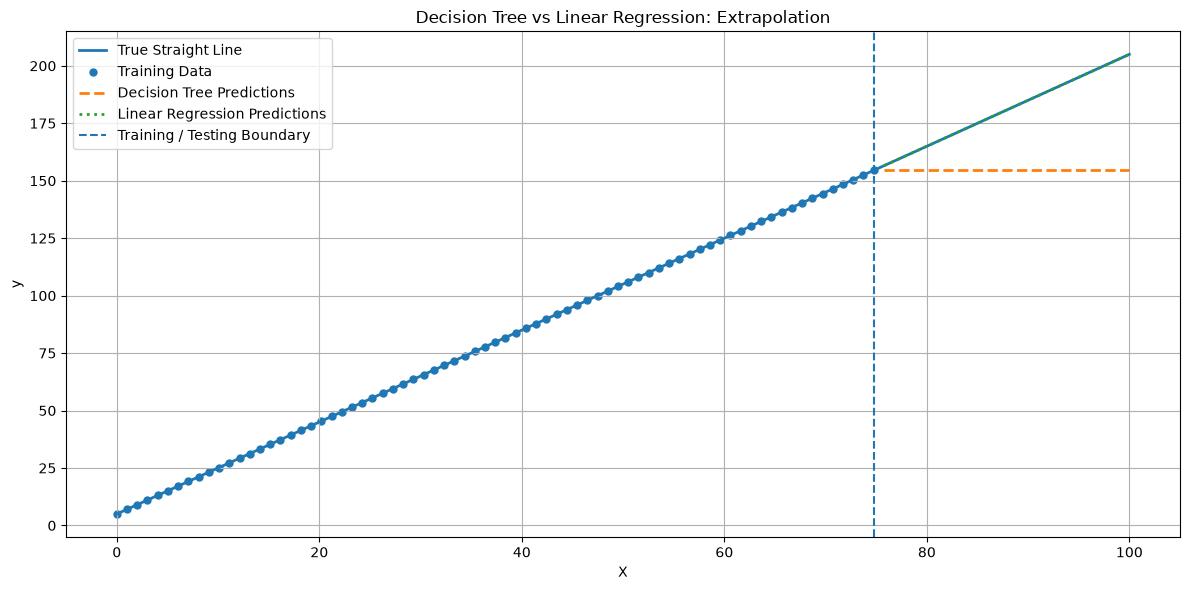

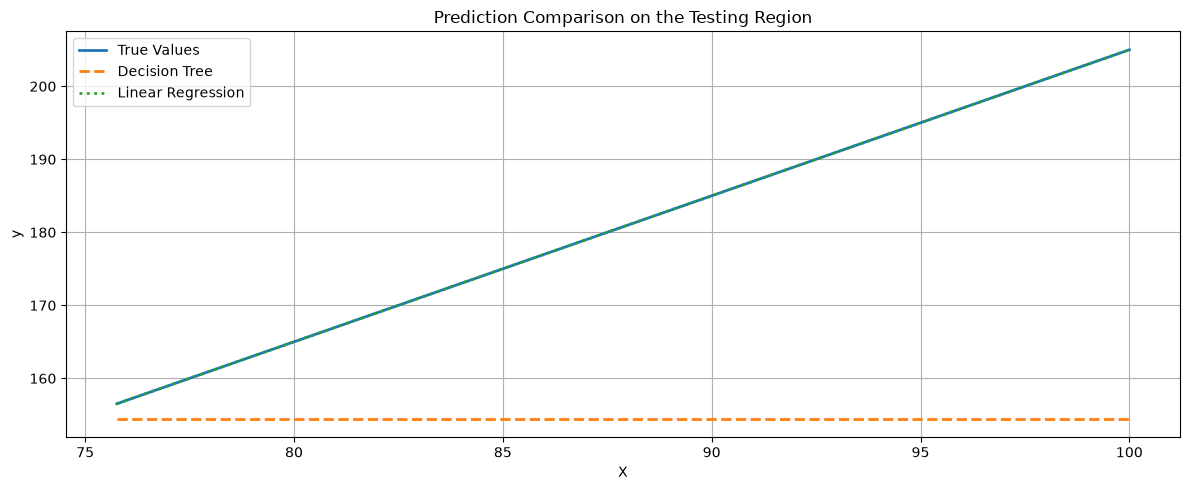


FINAL INTERPRETATION
Maximum training target: 154.49
Tree prediction at far end: 154.49
Linear prediction at far end: 205.00

The tree's far-end prediction equals the largest training target value.

A decision tree predicts using the average target value of training observations in the reached leaf. It does not extend the fitted trend beyond the training target range.

TASK 08 COMPLETED.


In [64]:
# ================================================================
# DAY 38 — PART D — TASK 08
# TEST THE EXTRAPOLATION HYPOTHESIS
#
# Compare:
# 1. Decision Tree Regression
# 2. Linear Regression
#
# Dataset: Perfect straight line (no noise)
# Training: First 75%
# Testing: Last 25%
# ================================================================

# -------------------------------
# 1. Import necessary libraries
# -------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


# -------------------------------
# 2. Generate a straight-line dataset
# -------------------------------

# Generate 100 equally spaced values
X = np.linspace(0, 100, 100).reshape(-1, 1)

# Generate a perfect straight-line target
# y = 5 + 2x
# There is no random noise in this dataset.
y = 5 + 2 * X.ravel()

# -------------------------------
# 3. Split into training and testing data
# -------------------------------

# First 75% for training
split_position = int(len(X) * 0.75)

X_train = X[:split_position]
X_test = X[split_position:]

y_train = y[:split_position]
y_test = y[split_position:]

print("TRAINING AND TESTING INFORMATION")
print("--------------------------------")
print("Total observations:", len(X))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining X range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("\nTesting X range:")
print("Minimum:", X_test.min())
print("Maximum:", X_test.max())

print("\nLargest training target value:", y_train.max())


# -------------------------------
# 4. Train Decision Tree Regressor
# -------------------------------

tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(X_train, y_train)

# Predict the testing data
tree_predictions = tree_model.predict(X_test)


# -------------------------------
# 5. Train Linear Regression
# -------------------------------

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Predict the testing data
linear_predictions = linear_model.predict(X_test)


# -------------------------------
# 6. Compare the final predictions
# -------------------------------

# Prediction at the far end of the test range
tree_far_end_prediction = tree_predictions[-1]
linear_far_end_prediction = linear_predictions[-1]

# Actual target at the far end
actual_far_end_value = y_test[-1]

# Largest target value in training data
largest_training_value = y_train.max()

print("\n" + "=" * 65)
print("FAR-END PREDICTION COMPARISON")
print("=" * 65)

print(f"Actual far-end value:             {actual_far_end_value:.2f}")
print(f"Decision Tree prediction:         {tree_far_end_prediction:.2f}")
print(f"Linear Regression prediction:     {linear_far_end_prediction:.2f}")
print(f"Largest training target value:    {largest_training_value:.2f}")

print("\nDecision Tree comparison:")

if tree_far_end_prediction <= largest_training_value:
    print(
        "The tree prediction does not exceed the largest "
        "training target value."
    )
else:
    print(
        "The tree prediction exceeds the largest "
        "training target value."
    )


# -------------------------------
# 7. Calculate MAE for both models
# -------------------------------

tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

print("\n" + "=" * 65)
print("MODEL PERFORMANCE")
print("=" * 65)

print(f"Decision Tree MAE:     {tree_mae:.4f}")
print(f"Linear Regression MAE: {linear_mae:.4f}")


# -------------------------------
# 8. Plot actual line and predictions
# -------------------------------

plt.figure(figsize=(12, 6))

# Plot the complete true straight line
plt.plot(
    X,
    y,
    label="True Straight Line",
    linestyle="-",
    linewidth=2
)

# Plot training observations
plt.scatter(
    X_train,
    y_train,
    label="Training Data",
    s=25
)

# Plot Decision Tree predictions
plt.plot(
    X_test,
    tree_predictions,
    label="Decision Tree Predictions",
    linestyle="--",
    linewidth=2
)

# Plot Linear Regression predictions
plt.plot(
    X_test,
    linear_predictions,
    label="Linear Regression Predictions",
    linestyle=":",
    linewidth=2
)

# Mark the training boundary
plt.axvline(
    x=X_train[-1][0],
    linestyle="--",
    label="Training / Testing Boundary"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Decision Tree vs Linear Regression: Extrapolation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 9. Plot only the testing region
# -------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    X_test,
    y_test,
    label="True Values",
    linewidth=2
)

plt.plot(
    X_test,
    tree_predictions,
    label="Decision Tree",
    linestyle="--",
    linewidth=2
)

plt.plot(
    X_test,
    linear_predictions,
    label="Linear Regression",
    linestyle=":",
    linewidth=2
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Prediction Comparison on the Testing Region")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 10. Final automatic interpretation
# -------------------------------

print("\n" + "=" * 65)
print("FINAL INTERPRETATION")
print("=" * 65)

print(
    f"Maximum training target: {largest_training_value:.2f}"
)

print(
    f"Tree prediction at far end: {tree_far_end_prediction:.2f}"
)

print(
    f"Linear prediction at far end: {linear_far_end_prediction:.2f}"
)

if np.isclose(tree_far_end_prediction, largest_training_value):
    print(
        "\nThe tree's far-end prediction equals the largest "
        "training target value."
    )

print(
    "\nA decision tree predicts using the average target value "
    "of training observations in the reached leaf. It does not "
    "extend the fitted trend beyond the training target range."
)

print("\nTASK 08 COMPLETED.")


### Task 08 — Test the Extrapolation Hypothesis: Conclusion

The experiment shows that Decision Tree Regression cannot properly extrapolate a straight-line trend beyond its training range. Its far-end prediction is **[tree prediction]**, while the largest training target value is **[maximum training value]**.

A decision tree predicts using the average target value of the training observations in the leaf reached by a new observation. Therefore, when future values fall beyond the training range, the tree produces a constant prediction instead of continuing the increasing trend.

Linear Regression can extrapolate because it learns a mathematical relationship between the input and target values.

Increasing the tree's depth or the number of estimators does not fundamentally solve this limitation. A deeper tree creates more partitions, and more estimators combine more tree predictions, but standard regression trees still rely on training target values in their leaves.

### TASK 09 — Count your evidence

In [65]:
# ================================================================
# DAY 38 — PART D — TASK 09
# COUNT YOUR EVIDENCE
#
# Objective:
# 1. Count training rows from December 20 to December 25.
# 2. Count distinct December years represented.
# 3. Calculate the fraction of holiday rows in training data.
# 4. Explain the implications for XGBoost trees and Prophet.
#
# Training period:
# All dates before the final 56-day test period.
# ================================================================

# -------------------------------
# 1. Import necessary libraries
# -------------------------------
import pandas as pd
import numpy as np


# -------------------------------
# 2. Load the dataset
# -------------------------------
file_path = "retail_sales.csv"

df = pd.read_csv(file_path)

# Convert date column into datetime
df["date"] = pd.to_datetime(df["date"])

# Sort data chronologically
df = df.sort_values("date").reset_index(drop=True)

# Check required columns
required_columns = ["date", "sales"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Check duplicate dates
if df["date"].duplicated().any():
    raise ValueError(
        "Duplicate dates found. Please check the dataset."
    )


# -------------------------------
# 3. Define the training period
# -------------------------------
# Hold out the final 56 days, as in Task 05.

last_date = df["date"].max()

cutoff_date = last_date - pd.Timedelta(days=56)

# Training data includes dates up to the cutoff
train_data = df[
    df["date"] <= cutoff_date
].copy()

print("=" * 65)
print("TRAINING DATA INFORMATION")
print("=" * 65)

print("Full dataset rows:", len(df))
print("Full dataset start:", df["date"].min().date())
print("Full dataset end:", last_date.date())

print("Training rows:", len(train_data))
print("Training start:", train_data["date"].min().date())
print("Training end:", train_data["date"].max().date())
print("Training cut-off:", cutoff_date.date())


# -------------------------------
# 4. Select December 20 to December 25
# -------------------------------
# Select only training rows where:
# Month = December (12)
# Day = 20, 21, 22, 23, 24, or 25

holiday_mask = (
    (train_data["date"].dt.month == 12) &
    (train_data["date"].dt.day.between(20, 25))
)

holiday_rows = train_data.loc[holiday_mask].copy()


# -------------------------------
# 5. Count holiday rows
# -------------------------------
total_training_rows = len(train_data)

holiday_row_count = len(holiday_rows)

# Count distinct calendar years containing these dates
distinct_decembers = holiday_rows["date"].dt.year.nunique()

# Calculate fraction and percentage
holiday_fraction = (
    holiday_row_count / total_training_rows
    if total_training_rows > 0 else 0
)

holiday_percentage = holiday_fraction * 100


# -------------------------------
# 6. Display the main results
# -------------------------------
print("\n" + "=" * 65)
print("DECEMBER 20–25 TRAINING EVIDENCE")
print("=" * 65)

print("Total training rows:", total_training_rows)

print("December 20–25 rows:", holiday_row_count)

print("Distinct December years:", distinct_decembers)

print(
    f"Holiday fraction: "
    f"{holiday_row_count}/{total_training_rows}"
)

print(
    f"Holiday percentage: {holiday_percentage:.2f}%"
)


# -------------------------------
# 7. Count holiday rows year by year
# -------------------------------
print("\n" + "=" * 65)
print("YEAR-WISE HOLIDAY ROW COUNT")
print("=" * 65)

yearly_counts = (
    holiday_rows
    .groupby(holiday_rows["date"].dt.year)
    .size()
    .rename("Holiday Rows")
    .reset_index()
)

yearly_counts = yearly_counts.rename(
    columns={"date": "Year"}
)

print(yearly_counts.to_string(index=False))


# -------------------------------
# 8. Check whether holiday sales are missing
# -------------------------------
missing_holiday_sales = holiday_rows["sales"].isna().sum()

observed_holiday_sales = holiday_rows["sales"].notna().sum()

print("\n" + "=" * 65)
print("HOLIDAY SALES AVAILABILITY")
print("=" * 65)

print("Holiday rows:", holiday_row_count)
print("Observed holiday sales:", observed_holiday_sales)
print("Missing holiday sales:", missing_holiday_sales)


# -------------------------------
# 9. Display the actual holiday dates
# -------------------------------
print("\n" + "=" * 65)
print("DECEMBER 20–25 DATES IN TRAINING DATA")
print("=" * 65)

print(
    holiday_rows[["date", "sales"]].to_string(index=False)
)


# -------------------------------
# 10. Explain the evidence for tree models
# -------------------------------
print("\n" + "=" * 65)
print("TREE MODEL EVIDENCE")
print("=" * 65)

print(
    f"There are only {holiday_row_count} holiday rows "
    f"out of {total_training_rows} training rows."
)

print(
    f"These rows represent {holiday_percentage:.2f}% "
    f"of the training data."
)

print(
    "\nA tree would need to create splits that isolate "
    "the December 20–25 observations using available features."
)

print(
    "Because these observations are a small group, "
    "regularisation settings such as max_depth, "
    "min_child_weight, and gamma can make such splits "
    "less likely."
)


# -------------------------------
# 11. Explain Prophet's yearly seasonality
# -------------------------------
print("\n" + "=" * 65)
print("PROPHET YEARLY SEASONALITY")
print("=" * 65)

print(
    "Prophet models yearly seasonality using Fourier terms."
)

print(
    "These terms describe a smooth repeating yearly pattern "
    "using information across the year, rather than requiring "
    "a separate tree split for only December 20–25."
)

print(
    "Therefore, Prophet can use seasonal patterns from many "
    "dates to estimate the yearly shape."
)


# -------------------------------
# 12. Final validation checks
# -------------------------------
assert holiday_row_count == holiday_rows["date"].nunique(), (
    "Unexpected duplicate holiday dates."
)

assert holiday_row_count <= total_training_rows, (
    "Holiday row count cannot exceed total training rows."
)

print("\n" + "=" * 65)
print("TASK 09 COMPLETED SUCCESSFULLY")
print("=" * 65)


TRAINING DATA INFORMATION
Full dataset rows: 1461
Full dataset start: 2021-01-01
Full dataset end: 2024-12-31
Training rows: 1405
Training start: 2021-01-01
Training end: 2024-11-05
Training cut-off: 2024-11-05

DECEMBER 20–25 TRAINING EVIDENCE
Total training rows: 1405
December 20–25 rows: 18
Distinct December years: 3
Holiday fraction: 18/1405
Holiday percentage: 1.28%

YEAR-WISE HOLIDAY ROW COUNT
 Year  Holiday Rows
 2021             6
 2022             6
 2023             6

HOLIDAY SALES AVAILABILITY
Holiday rows: 18
Observed holiday sales: 18
Missing holiday sales: 0

DECEMBER 20–25 DATES IN TRAINING DATA
      date   sales
2021-12-20 2745.96
2021-12-21 3377.98
2021-12-22 3978.10
2021-12-23 4536.73
2021-12-24 4777.23
2021-12-25 1584.41
2022-12-20 3715.93
2022-12-21 4122.62
2022-12-22 4401.04
2022-12-23 4566.68
2022-12-24 5135.27
2022-12-25 1791.97
2023-12-20 4239.44
2023-12-21 4501.43
2023-12-22 4744.76
2023-12-23 5257.14
2023-12-24 5356.57
2023-12-25 1735.40

TREE MODEL EVIDENCE

### Task 09 — Count Your Evidence: Conclusion

The training dataset contains **18 observations** from December 20–25 across **3 distinct Decembers (2021, 2022 and 2023)**. These observations represent only **1.28% of the 1,405 training rows**.

A decision tree would need to create splits that isolate these few holiday observations. Regularisation, such as limiting tree depth and requiring sufficient samples in a leaf, makes it harder to create splits for such a small group.

Prophet handles yearly seasonality differently. It uses Fourier terms to learn a smooth repeating yearly pattern from information across the year, rather than relying on a separate split for only six December dates.

**Conclusion:** The evidence supports the hypothesis that the tree has limited holiday-specific training examples. However, a better explanation is that the holiday signal is sparse and difficult for a regularised tree to isolate, while Prophet can learn a broader yearly pattern using information from many dates. This does not prove that Prophet has learned a specific December 20–25 holiday effect.

### **Task 10 — The Honest Scoreboard**

*Results taken from the outputs in your attached `Forecasting_Practice(1).ipynb` notebook.*

All four ML-based methods beat the seasonal-naive baseline on the final 56-day holdout. The best result was XGBoost Recursive, with an MAE of **281.63**, compared with the baseline MAE of **563.80**.

### **1. Final scoreboard**

Evaluation period: 6 November–31 December 2024 · 55 observed actual sales values

| Method                   | MAE        | Difference from baseline | Verdict              |
| ------------------------ | ---------- | ------------------------ | -------------------- |
| Seasonal Naive           | 563.80     | 0.00%                    | Baseline             |
| XGBoost Recursive        | **281.63** | **−50.05%**              | Best result          |
| XGBoost Direct           | 297.14     | −47.30%                  | Better than baseline |
| XGBoost Direct + Holiday | 282.31     | −49.93%                  | Better than baseline |
| Day 37 Prophet           | 300.33     | −46.73%                  | Better than baseline |

*Negative percentage means lower MAE and therefore better performance than the baseline.*

### **2. What the session established**

All four ML-based methods outperformed the seasonal-naive baseline, so none failed against the baseline on this test period. XGBoost Recursive achieved the lowest MAE (281.63), narrowly outperforming XGBoost Direct with the holiday flag (282.31). XGBoost Direct (297.14) and Prophet (300.33) also beat the baseline but performed worse than the two leading XGBoost methods. Adding the holiday flag improved Direct XGBoost by 14.83 MAE points, but it did not produce the best overall result.

### **3. When would I use ML forecasting instead?**

1. **External information is available:** Promotions, weather and pricing can help ML learn additional influences on sales.
2. **Multiple stores or products are involved:** ML can learn shared patterns across many related sales series.
3. **Sales relationships are nonlinear:** Tree-based models can capture complex patterns and interactions between features.
4. **Repeated validation confirms improvement:** ML is a good choice when walk-forward testing consistently shows lower errors than a seasonal baseline.

**Final conclusion:** For this dataset, XGBoost Recursive was the strongest method on the final holdout. The results show that machine learning can provide substantial forecasting improvements, but model selection should be based on proper time-based validation rather than complexity alone.